# Sales Forecasting MyVentory — Eksperimen Gabungan (Statistik, ML, DL)

Notebook ini menyatukan tiga pendekatan peramalan **NetSales harian per outlet** dengan **satu metodologi yang sama**, yaitu metodologi model global CatBoost:

| Blok | Keluarga model | Model |
|---|---|---|
| **A** | statistik (univariat per outlet) | SARIMA, ETS (Holt-Winters) |
| **B** | machine learning (model global, `outlet_id` sebagai fitur) | CatBoost, LightGBM, XGBoost, Gradient Boosting |
| **C** | deep learning (model global + embedding outlet) | LSTM |

**Metodologi yang dipakai seragam (mengacu notebook `sales_forecast_global_catboost`):**

1. data diagregasi per `date` x `outlet_id` (panel lengkap, hari tanpa transaksi = 0);
2. split **kronologis** train - validation - test (28/28/28 hari terakhir);
3. fitur lag 1/7/14/28, rolling mean & std 7/14/28, kalender, dan `outlet_id` — semua memakai nilai **sebelum** hari prediksi (tanpa kebocoran);
4. peramalan 28 hari data uji dilakukan **per outlet** lalu dijumlahkan menjadi total;
5. model ML/DL bersifat **global** (satu model untuk semua outlet), model statistik bersifat univariat sehingga dilatih per outlet tetapi dievaluasi dengan agregasi yang sama;
6. metrik seragam: MAE, RMSE, MAPE, sMAPE, bias;
7. model terbaik dilatih ulang pada seluruh data dan disimpan beserta metadata.

Keluaran: `artifacts/sales_forecast_exp/`.

> **Tambahan:** Bagian **18** berisi eksperimen pembanding delapan metode dengan strategi model global. Hasilnya disimpan terpisah di `artifacts/sales_forecast_exp_comparison/`, tanpa menimpa hasil asli.

Environment: conda `Machine-Learning` (Python 3.11, TensorFlow 2.19).

## 1. Konfigurasi

Path, parameter, dan folder keluaran berada di satu tempat.

In [1]:
import importlib.metadata as metadata_pkg
import json
import os
import pickle
import random
import shutil
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["PYTHONHASHSEED"] = "42"

DATA_PATH = Path("..") / "data" / "Transactions.csv"
OUTPUT_DIR = Path("..") / "artifacts" / "sales_forecast_exp"
METADATA_PATH = OUTPUT_DIR / "metadata.json"
BUNDLE_PATH = OUTPUT_DIR / "model.pkl"

TARGET = "net_sales"
ID_COLUMNS = ["date", "outlet_id"]

TEST_DAYS = 28
VAL_DAYS = 28
SEASON_LENGTH = 7
HORIZON_DAYS = 7
WINDOW = 28
LAGS = [1, 7, 14, 28]
ROLLS = [7, 14, 28]
EPOCHS = 200
BATCH_SIZE = 16
SEED = 42

CALENDAR_FEATURES = ["dow", "is_weekend", "day", "month", "day_of_year", "week_of_year"]
NUMERIC_FEATURES = (
    [f"lag_{lag}" for lag in LAGS]
    + [f"roll_mean_{window}" for window in ROLLS]
    + [f"roll_std_{window}" for window in ROLLS]
    + CALENDAR_FEATURES
)
FEATURES = NUMERIC_FEATURES + ["outlet_id"]
CAT_FEATURES = ["outlet_id"]

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

print("python      :", sys.version.split()[0])
print("pandas      :", pd.__version__)
for package in ["tensorflow", "catboost", "lightgbm", "xgboost", "scikit-learn", "statsmodels"]:
    try:
        print(f"{package:<12}:", metadata_pkg.version(package))
    except metadata_pkg.PackageNotFoundError:
        print(f"{package:<12}: tidak terpasang")
print("folder hasil:", OUTPUT_DIR.resolve())

python      : 3.11.11
pandas      : 2.2.3
tensorflow  : 2.19.0
catboost    : 1.2.10
lightgbm    : 4.6.0
xgboost     : 3.0.2
scikit-learn: 1.6.1
statsmodels : 0.15.0
folder hasil: C:\Users\Radit\Politeknik Negeri Malang\Semester 5\ProjectBasedLearning_MyVentory\ML\artifacts\sales_forecast_exp


## 2. Agregasi data ke panel tanggal x outlet

Satu baris transaksi = satu struk. NetSales dijumlahkan per `date` x `outlet_id`, lalu panel dilengkapi kalender penuh agar setiap outlet memiliki satu baris untuk setiap hari.

In [2]:
transactions = pd.read_csv(DATA_PATH, parse_dates=["Date"])

aggregated = (
    transactions.groupby(["Date", "Outlet"], as_index=False)
    .NetSales.sum()
    .rename(columns={"Date": "date", "Outlet": "outlet_id", "NetSales": TARGET})
)

outlets = sorted(aggregated["outlet_id"].astype(str).unique())
full_dates = pd.date_range(aggregated["date"].min(), aggregated["date"].max(), freq="D")

panel = (
    aggregated.assign(outlet_id=aggregated["outlet_id"].astype(str))
    .set_index(ID_COLUMNS)
    .reindex(pd.MultiIndex.from_product([full_dates, outlets], names=ID_COLUMNS))
    .reset_index()
    .fillna({TARGET: 0.0})
    .sort_values(ID_COLUMNS)
    .reset_index(drop=True)
)

assert panel[TARGET].notna().all(), "ada hari tanpa nilai penjualan"
assert not panel.duplicated(ID_COLUMNS).any(), "ada pasangan tanggal-outlet duplikat"

total_daily = panel.groupby("date")[TARGET].sum()

print(f"baris transaksi : {len(transactions):,}")
print(f"outlet          : {outlets}")
print(f"rentang tanggal : {panel.date.min().date()} s/d {panel.date.max().date()}")
print(f"jumlah hari     : {panel.date.nunique()}")
print(f"jumlah baris    : {len(panel):,} (hari x outlet)")
print()
print("total NetSales per outlet (juta rupiah):")
print((panel.groupby("outlet_id")[TARGET].sum() / 1e6).round(1).to_string())

baris transaksi : 53,820
outlet          : ['SHOP001', 'SHOP002', 'SHOP003']
rentang tanggal : 2025-01-02 s/d 2025-09-30
jumlah hari     : 272
jumlah baris    : 816 (hari x outlet)

total NetSales per outlet (juta rupiah):
outlet_id
SHOP001    580.3
SHOP002    235.7
SHOP003    368.9


## 3. Eksplorasi awal

Skala antar outlet berbeda, pola mingguan kuat, dan keduanya menentukan bentuk fitur serta arsitektur model.

In [3]:
summary = panel.groupby("outlet_id")[TARGET].agg(["mean", "std", "min", "median", "max"]) / 1e6
print("Statistik harian per outlet (juta rupiah):")
print(summary.round(2).to_string())
print()
print("NetSales total per bulan (juta rupiah):")
print((total_daily.resample("MS").sum() / 1e6).round(1).to_string())

Statistik harian per outlet (juta rupiah):
           mean   std   min  median   max
outlet_id                                
SHOP001    2.13  0.32  1.48    2.11  2.94
SHOP002    0.87  0.27  0.30    0.82  1.66
SHOP003    1.36  0.35  0.46    1.40  2.06

NetSales total per bulan (juta rupiah):
date
2025-01-01    118.2
2025-02-01    134.4
2025-03-01    137.3
2025-04-01     99.3
2025-05-01    119.5
2025-06-01    164.7
2025-07-01    158.8
2025-08-01    131.2
2025-09-01    121.6
Freq: MS


In [4]:
from statsmodels.tsa.seasonal import STL

stl = STL(total_daily.asfreq("D"), period=SEASON_LENGTH, robust=True).fit()
strength = max(0.0, 1 - stl.resid.var() / total_daily.var())

print(f"kekuatan pola mingguan (0 sampai 1): {strength:.3f}")
print("nilai di atas 0.5 berarti pola mingguan jelas dan layak dimodelkan.")

kekuatan pola mingguan (0 sampai 1): 0.770
nilai di atas 0.5 berarti pola mingguan jelas dan layak dimodelkan.


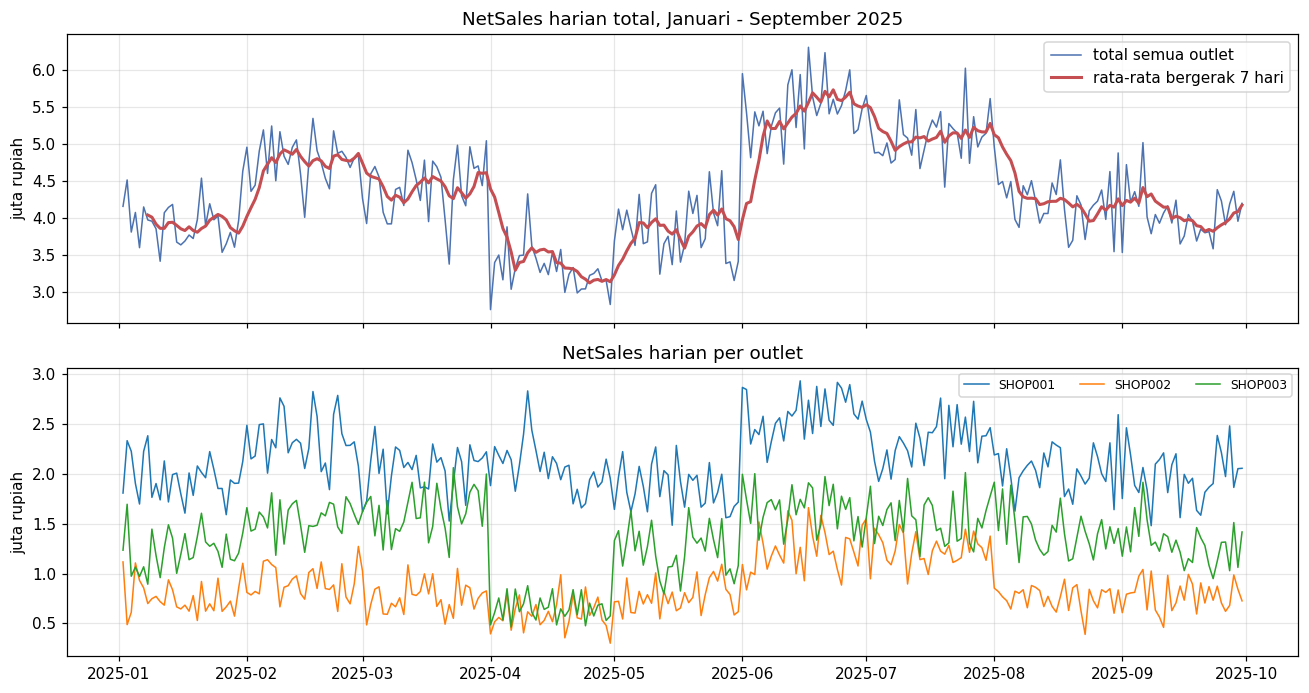

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6.4), sharex=True)

axes[0].plot(total_daily.index, total_daily / 1e6, lw=1, color="#4c72b0", label="total semua outlet")
axes[0].plot(total_daily.index, total_daily.rolling(7).mean() / 1e6, lw=2, color="#c44e52", label="rata-rata bergerak 7 hari")
axes[0].set_title("NetSales harian total, Januari - September 2025")
axes[0].set_ylabel("juta rupiah")
axes[0].legend()

palette = plt.rcParams["axes.prop_cycle"].by_key()["color"]
for index, outlet in enumerate(outlets):
    series = panel[panel.outlet_id == outlet].set_index("date")[TARGET]
    axes[1].plot(series.index, series / 1e6, lw=1, label=outlet, color=palette[index % len(palette)])

axes[1].set_title("NetSales harian per outlet")
axes[1].set_ylabel("juta rupiah")
axes[1].legend(ncol=len(outlets), fontsize=8)

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "fig_1_series.png", dpi=120)
plt.show()

## 4. Split kronologis

| Blok | Fungsi |
|---|---|
| train | melatih model, dipakai memilih hyperparameter statistik |
| validation | early stopping dan pemilihan hyperparameter ML |
| test | evaluasi akhir, tidak disentuh saat pelatihan |

Model final untuk data uji dilatih pada **train + validation**, sehingga 28 hari terakhir murni menjadi data uji.

In [6]:
all_dates = pd.DatetimeIndex(sorted(panel["date"].unique()))

test_dates = all_dates[-TEST_DAYS:]
val_dates = all_dates[-(TEST_DAYS + VAL_DAYS):-TEST_DAYS]
train_dates = all_dates[:-(TEST_DAYS + VAL_DAYS)]
trainval_dates = train_dates.append(val_dates)

assert train_dates.max() < val_dates.min() < val_dates.max() < test_dates.min(), "urutan split salah"

train_panel = panel[panel.date.isin(train_dates)]
val_panel = panel[panel.date.isin(val_dates)]
test_panel = panel[panel.date.isin(test_dates)]
hist_panel = panel[panel.date.isin(trainval_dates)]

print(f"train      : {pd.Timestamp(train_dates.min()).date()} s/d {pd.Timestamp(train_dates.max()).date()}  ({len(train_dates)} hari, {len(train_panel)} baris)")
print(f"validation : {pd.Timestamp(val_dates.min()).date()} s/d {pd.Timestamp(val_dates.max()).date()}  ({len(val_dates)} hari, {len(val_panel)} baris)")
print(f"test       : {pd.Timestamp(test_dates.min()).date()} s/d {pd.Timestamp(test_dates.max()).date()}  ({len(test_dates)} hari, {len(test_panel)} baris)")
print()
print(f"rata-rata harian train : Rp {train_panel.groupby('date')[TARGET].sum().mean():,.0f}")
print(f"rata-rata harian test  : Rp {test_panel.groupby('date')[TARGET].sum().mean():,.0f}")

train      : 2025-01-02 s/d 2025-08-05  (216 hari, 648 baris)
validation : 2025-08-06 s/d 2025-09-02  (28 hari, 84 baris)
test       : 2025-09-03 s/d 2025-09-30  (28 hari, 84 baris)

rata-rata harian train : Rp 4,420,504
rata-rata harian test  : Rp 4,047,619


## 5. Feature engineering (dipakai blok ML)

Fitur dibentuk dari nilai **sebelum** hari yang diprediksi (`shift`), sehingga tidak ada informasi masa depan yang masuk.

- `lag_1/7/14/28`: level penjualan pada siklus harian dan mingguan sebelumnya;
- `roll_mean_7/14/28`, `roll_std_7/14/28`: level dan volatilitas jangka pendek;
- `dow`, `is_weekend`, `day`, `month`, `day_of_year`, `week_of_year`: pola kalender;
- `outlet_id`: fitur kategorikal yang membuat satu model bisa membedakan outlet.

In [7]:
def build_features(frame):
    data = frame.sort_values(ID_COLUMNS).reset_index(drop=True).copy()
    data["outlet_id"] = data["outlet_id"].astype(str)

    data["dow"] = data["date"].dt.dayofweek
    data["is_weekend"] = (data["dow"] >= 5).astype(int)
    data["day"] = data["date"].dt.day
    data["month"] = data["date"].dt.month
    data["day_of_year"] = data["date"].dt.dayofyear
    data["week_of_year"] = data["date"].dt.isocalendar().week.astype(int)

    grouped = data.groupby("outlet_id", sort=False)[TARGET]
    for lag in LAGS:
        data[f"lag_{lag}"] = grouped.shift(lag)

    previous = grouped.shift(1)
    for window in ROLLS:
        data[f"roll_mean_{window}"] = previous.groupby(data["outlet_id"], sort=False).transform(
            lambda values: values.rolling(window).mean()
        )
        data[f"roll_std_{window}"] = previous.groupby(data["outlet_id"], sort=False).transform(
            lambda values: values.rolling(window).std()
        )

    return data


def drop_unusable(frame):
    return frame.dropna(subset=FEATURES + [TARGET]).reset_index(drop=True)


feature_panel = build_features(panel)

train_df = drop_unusable(feature_panel[feature_panel.date.isin(train_dates)])
val_df = drop_unusable(feature_panel[feature_panel.date.isin(val_dates)])
trainval_df = drop_unusable(feature_panel[feature_panel.date.isin(trainval_dates)])
full_df = drop_unusable(feature_panel)

print(f"matriks train      : {train_df.shape}")
print(f"matriks validation : {val_df.shape}")
print(f"matriks train+val  : {trainval_df.shape}")
print()
print("contoh baris train terakhir:")
print(train_df.tail(1)[FEATURES].round(1).to_string(index=False))

matriks train      : (564, 19)
matriks validation : (84, 19)
matriks train+val  : (648, 19)

contoh baris train terakhir:
    lag_1     lag_7    lag_14    lag_28  roll_mean_7  roll_mean_14  roll_mean_28  roll_std_7  roll_std_14  roll_std_28  dow  is_weekend  day  month  day_of_year  week_of_year outlet_id
1293693.7 1457657.7 1827027.0 1330630.6    1622779.9     1567889.3     1545495.5    236016.4     266073.8     241397.4    1           0    5      8          217            32   SHOP003


In [8]:
sample_date = pd.Timestamp(val_dates[0])

for outlet in outlets:
    expected = (
        panel[(panel.outlet_id == outlet) & (panel.date < sample_date)]
        .sort_values("date")[TARGET]
        .iloc[-1]
    )
    observed = feature_panel[(feature_panel.outlet_id == outlet) & (feature_panel.date == sample_date)].lag_1.iloc[0]
    assert np.isclose(observed, expected), f"lag_1 {outlet} tidak sesuai riwayat"

print("cek kebocoran lolos: seluruh fitur hanya memakai nilai sebelum hari prediksi")
print(f"hari target maksimum di train : {train_df.date.max().date()}")
print(f"hari minimum di test          : {pd.Timestamp(test_dates[0]).date()}")

cek kebocoran lolos: seluruh fitur hanya memakai nilai sebelum hari prediksi
hari target maksimum di train : 2025-08-05
hari minimum di test          : 2025-09-03


## 6. Baseline seasonal-naive (Naive-7)

`y(t) = y(t-7)`, dihitung per outlet lalu dijumlahkan. Baseline ini menjadi acuan minimal yang harus dikalahkan setiap model.

In [9]:
def naive_forecast(history, start_dates, season_length=SEASON_LENGTH):
    frames = []
    for outlet in outlets:
        last_week = (
            history[history.outlet_id == outlet]
            .sort_values("date")[TARGET]
            .to_numpy()[-season_length:]
        )
        for position, date in enumerate(start_dates):
            frames.append({"date": date, "outlet_id": outlet,
                           "prediction": last_week[position % season_length]})
    return pd.DataFrame(frames)


forecast_baseline = naive_forecast(hist_panel, test_dates)

forecasts = {"Naive-7": forecast_baseline}
families = {"Naive-7": "baseline"}

print(f"bentuk prediksi baseline: {forecast_baseline.shape}")
print(forecast_baseline.head(6).assign(prediction=lambda frame: frame.prediction.round(0)).to_string(index=False))

bentuk prediksi baseline: (84, 3)
      date outlet_id  prediction
2025-09-03   SHOP001   2001802.0
2025-09-04   SHOP001   1924324.0
2025-09-05   SHOP001   2312613.0
2025-09-06   SHOP001   1641441.0
2025-09-07   SHOP001   2595496.0
2025-09-08   SHOP001   1753153.0


## 7. Blok A — Model Statistik

Model statistik bersifat **univariat**, sehingga dilatih per outlet pada deret waktu masing-masing outlet. Hasil per outlet digabung menjadi satu tabel prediksi dengan format yang sama seperti blok ML, lalu dijumlahkan menjadi total.

Konfigurasi identik dengan notebook `sales_forecast`: SARIMA dengan grid AIC dan musiman mingguan 7 hari, ETS dengan tren aditif damping + musiman aditif.

### 7.1 A1 — SARIMA per outlet

Grid kecil `(p,1,q) x (P,1,Q,7)` dicari dengan AIC **hanya pada data train**. Order terpilih kemudian dilatih ulang pada **train + validation** sebelum meramal data uji, sehingga jarak ramalan tepat 28 hari dan data uji tetap tidak tersentuh.

In [10]:
from statsmodels.tsa.statespace.sarimax import SARIMAX


def outlet_series(frame, outlet):
    return (
        frame[frame.outlet_id == outlet]
        .sort_values("date")
        .set_index("date")[TARGET]
        .asfreq("D")
    )


sarima_grid = []
sarima_config = {}
sarima_models = {}

for outlet in outlets:
    series = outlet_series(train_panel, outlet)

    candidates = []
    for p in range(3):
        for q in range(3):
            for P in range(2):
                for Q in range(2):
                    try:
                        candidate = SARIMAX(
                            series,
                            order=(p, 1, q),
                            seasonal_order=(P, 1, Q, SEASON_LENGTH),
                            enforce_stationarity=False,
                            enforce_invertibility=False,
                        ).fit(disp=False)
                        candidates.append({"outlet_id": outlet, "p": p, "d": 1, "q": q,
                                           "P": P, "D": 1, "Q": Q, "AIC": candidate.aic})
                    except Exception:
                        pass

    table = pd.DataFrame(candidates).sort_values("AIC").reset_index(drop=True)
    best = table.loc[0]
    best_order = (int(best.p), 1, int(best.q))
    best_seasonal = (int(best.P), 1, int(best.Q), SEASON_LENGTH)

    sarima_models[outlet] = SARIMAX(
        outlet_series(hist_panel, outlet),
        order=best_order,
        seasonal_order=best_seasonal,
        enforce_stationarity=False,
        enforce_invertibility=False,
    ).fit(disp=False)
    sarima_config[outlet] = {"order": best_order, "seasonal_order": best_seasonal, "AIC": float(best.AIC)}
    sarima_grid.append(table.assign(terpilih=False).assign(terpilih=lambda frame: frame.AIC == frame.AIC.min()))

for outlet, config in sarima_config.items():
    print(f"{outlet}: order {config['order']} x {config['seasonal_order']}  AIC {config['AIC']:,.1f}")

forecast_sarima = pd.concat(
    [
        pd.DataFrame({
            "date": test_dates,
            "outlet_id": outlet,
            "prediction": np.asarray(sarima_models[outlet].forecast(TEST_DAYS), dtype=float),
        })
        for outlet in outlets
    ],
    ignore_index=True,
)

forecasts["SARIMA"] = forecast_sarima
families["SARIMA"] = "stat"

print()
print("tujuh prediksi total pertama (rupiah):",
      np.round(forecast_sarima.groupby("date").prediction.sum().to_numpy()[:7]).astype(int).tolist())

c:\Users\Radit\anaconda3\envs\Machine-Learning\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Radit\anaconda3\envs\Machine-Learning\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


SHOP001: order (2, 1, 2) x (1, 1, 1, 7)  AIC 5,581.0
SHOP002: order (2, 1, 2) x (1, 1, 1, 7)  AIC 5,449.1
SHOP003: order (1, 1, 2) x (1, 1, 1, 7)  AIC 5,579.5

tujuh prediksi total pertama (rupiah): [4218636, 4224031, 4464659, 4096458, 4458033, 4230757, 4240368]


### 7.2 A2 — ETS (Holt-Winters) per outlet

Tren aditif dengan damping dan komponen musiman mingguan. Parameter smoothing diestimasi otomatis per outlet pada data **train + validation**, lalu model meramal 28 hari data uji.

In [11]:
from statsmodels.tsa.exponential_smoothing.ets import ETSModel


ets_models = {}
ets_config = {}

for outlet in outlets:
    series = outlet_series(hist_panel, outlet)
    model = ETSModel(
        series,
        error="add",
        trend="add",
        damped_trend=True,
        seasonal="add",
        seasonal_periods=SEASON_LENGTH,
    ).fit(disp=False)

    ets_models[outlet] = model
    smoothing = dict(zip(model.param_names, model.params))
    ets_config[outlet] = {
        key: round(float(smoothing[key]), 4)
        for key in ["smoothing_level", "smoothing_trend", "smoothing_seasonal", "damping_trend"]
        if key in smoothing
    }

print("parameter smoothing hasil estimasi per outlet:")
for outlet, config in ets_config.items():
    print(f"  {outlet}: {config}")

forecast_ets = pd.concat(
    [
        pd.DataFrame({
            "date": test_dates,
            "outlet_id": outlet,
            "prediction": np.asarray(ets_models[outlet].forecast(TEST_DAYS), dtype=float),
        })
        for outlet in outlets
    ],
    ignore_index=True,
)

forecasts["ETS"] = forecast_ets
families["ETS"] = "stat"

print()
print("tujuh prediksi total pertama (rupiah):",
      np.round(forecast_ets.groupby("date").prediction.sum().to_numpy()[:7]).astype(int).tolist())

parameter smoothing hasil estimasi per outlet:
  SHOP001: {'smoothing_level': 0.2418, 'smoothing_trend': 0.0, 'smoothing_seasonal': 0.0478, 'damping_trend': 0.8}
  SHOP002: {'smoothing_level': 0.1807, 'smoothing_trend': 0.0087, 'smoothing_seasonal': 0.0708, 'damping_trend': 0.9139}
  SHOP003: {'smoothing_level': 0.3092, 'smoothing_trend': 0.0, 'smoothing_seasonal': 0.0549, 'damping_trend': 0.9546}

tujuh prediksi total pertama (rupiah): [4228925, 4234860, 4391627, 4096373, 4355056, 4183655, 4263168]


## 8. Blok B — Model Machine Learning (global)

Semua model di blok ini adalah **satu model global** untuk ketiga outlet, dengan matriks fitur yang identik. Peramalan 28 hari dilakukan **rekursif per outlet**: prediksi hari ini masuk ke riwayat dan menjadi fitur hari berikutnya.

Fungsi `recursive_forecast_ml` dipakai bersama agar tidak ada duplikasi logika di antara model.

In [12]:
OUTLET_CODES = {outlet: index for index, outlet in enumerate(outlets)}


def categorical_frame(frame):
    data = frame[FEATURES].copy()
    data["outlet_id"] = pd.Categorical(data["outlet_id"], categories=outlets)
    return data


def numeric_frame(frame):
    data = frame[FEATURES].copy()
    data["outlet_id"] = data["outlet_id"].map(OUTLET_CODES).astype(int)
    return data


def recursive_forecast_ml(predict_fn, history, start_date, steps):
    data = history[["date", "outlet_id", TARGET]].copy()
    collected = []

    for step in range(steps):
        target_date = pd.Timestamp(start_date) + pd.Timedelta(days=step)
        placeholder = pd.DataFrame({
            "date": [target_date] * len(outlets),
            "outlet_id": outlets,
            TARGET: [np.nan] * len(outlets),
        })
        candidate = build_features(pd.concat([data, placeholder], ignore_index=True))
        current = candidate[candidate.date == target_date].copy()
        current[TARGET] = predict_fn(current)
        collected.append(current[["date", "outlet_id", TARGET]])
        data = pd.concat([data, current[["date", "outlet_id", TARGET]]], ignore_index=True)

    forecast = pd.concat(collected, ignore_index=True)
    return forecast.rename(columns={TARGET: "prediction"})

### 8.1 B1 — CatBoost global (model acuan)

Hyperparameter dicari dengan grid kecil yang dinilai **hanya pada validation** (12 kombinasi: loss `MAE`/`RMSE` x depth x learning rate). Model terbaik dilatih ulang pada train + validation.

In [13]:
from catboost import CatBoostRegressor, Pool

pool_train = Pool(train_df[FEATURES], train_df[TARGET], cat_features=CAT_FEATURES)
pool_val = Pool(val_df[FEATURES], val_df[TARGET], cat_features=CAT_FEATURES)

catboost_grid = []
for loss_function in ["MAE", "RMSE"]:
    for depth in [3, 4, 6]:
        for learning_rate in [0.02, 0.03]:
            candidate = CatBoostRegressor(
                iterations=3000,
                learning_rate=learning_rate,
                depth=depth,
                l2_leaf_reg=3.0,
                loss_function=loss_function,
                eval_metric="MAE",
                random_seed=SEED,
                od_type="Iter",
                od_wait=150,
                verbose=False,
                allow_writing_files=False,
            )
            candidate.fit(pool_train, eval_set=pool_val, use_best_model=True)
            catboost_grid.append({
                "loss": loss_function,
                "depth": depth,
                "lr": learning_rate,
                "iterations": int(candidate.get_best_iteration()) + 1,
                "val_MAE": float(candidate.get_best_score()["validation"]["MAE"]),
            })

catboost_table = pd.DataFrame(catboost_grid).sort_values("val_MAE").reset_index(drop=True)
best_cat = catboost_table.loc[0]

CATBOOST_CONFIG = {
    "loss_function": str(best_cat.loss),
    "depth": int(best_cat.depth),
    "learning_rate": float(best_cat.lr),
    "iterations": int(best_cat.iterations),
}

print(f"kombinasi diuji: {len(catboost_table)}")
print(catboost_table.head(5).round(2).to_string(index=False))
print()
print("konfigurasi terpilih:", CATBOOST_CONFIG)

catboost_model = CatBoostRegressor(
    **CATBOOST_CONFIG,
    l2_leaf_reg=3.0,
    eval_metric="MAE",
    random_seed=SEED,
    verbose=False,
    allow_writing_files=False,
)
catboost_model.fit(Pool(trainval_df[FEATURES], trainval_df[TARGET], cat_features=CAT_FEATURES))

forecast_catboost = recursive_forecast_ml(
    lambda frame: catboost_model.predict(frame[FEATURES]),
    hist_panel,
    test_dates[0],
    TEST_DAYS,
)

forecasts["CatBoost Global"] = forecast_catboost
families["CatBoost Global"] = "ml"

print()
print("tujuh prediksi total pertama (rupiah):",
      np.round(forecast_catboost.groupby("date").prediction.sum().to_numpy()[:7]).astype(int).tolist())

kombinasi diuji: 12
loss  depth   lr  iterations   val_MAE
 MAE      3 0.02         975 150547.55
 MAE      4 0.02         965 150564.04
 MAE      3 0.03         822 152545.81
 MAE      4 0.03         317 156139.02
RMSE      3 0.03         344 159669.23

konfigurasi terpilih: {'loss_function': 'MAE', 'depth': 3, 'learning_rate': 0.02, 'iterations': 975}

tujuh prediksi total pertama (rupiah): [4329639, 4278437, 4252384, 4111204, 4149773, 4190602, 4220499]


### 8.2 B2 — LightGBM global

Gradient boosting berbasis histogram dengan `outlet_id` sebagai fitur kategorikal.

In [14]:
from lightgbm import LGBMRegressor

lgbm_model = LGBMRegressor(
    n_estimators=800,
    learning_rate=0.03,
    num_leaves=31,
    subsample=0.9,
    colsample_bytree=0.9,
    random_state=SEED,
    verbose=-1,
)
lgbm_model.fit(categorical_frame(trainval_df), trainval_df[TARGET])

forecast_lgbm = recursive_forecast_ml(
    lambda frame: lgbm_model.predict(categorical_frame(frame)),
    hist_panel,
    test_dates[0],
    TEST_DAYS,
)

forecasts["LightGBM Global"] = forecast_lgbm
families["LightGBM Global"] = "ml"

print("tujuh prediksi total pertama (rupiah):",
      np.round(forecast_lgbm.groupby("date").prediction.sum().to_numpy()[:7]).astype(int).tolist())

tujuh prediksi total pertama (rupiah): [4157341, 4185008, 4282975, 4176116, 4144996, 4113773, 4105225]


### 8.3 B3 — XGBoost global

In [15]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=800,
    learning_rate=0.03,
    max_depth=4,
    subsample=0.9,
    colsample_bytree=0.9,
    tree_method="hist",
    enable_categorical=True,
    random_state=SEED,
)
xgb_model.fit(categorical_frame(trainval_df), trainval_df[TARGET])

forecast_xgb = recursive_forecast_ml(
    lambda frame: xgb_model.predict(categorical_frame(frame)),
    hist_panel,
    test_dates[0],
    TEST_DAYS,
)

forecasts["XGBoost Global"] = forecast_xgb
families["XGBoost Global"] = "ml"

print("tujuh prediksi total pertama (rupiah):",
      np.round(forecast_xgb.groupby("date").prediction.sum().to_numpy()[:7]).astype(int).tolist())

tujuh prediksi total pertama (rupiah): [4015232, 4199486, 4232120, 4106191, 4119284, 4264151, 4148634]


### 8.4 B4 — Gradient Boosting (scikit-learn) global

Versi scikit-learn dari Gradient Boosting, dengan `outlet_id` dikodekan sebagai bilangan bulat karena implementasinya belum mendukung fitur kategorikal langsung.

In [16]:
from sklearn.ensemble import GradientBoostingRegressor

gbr_model = GradientBoostingRegressor(
    n_estimators=400,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.9,
    random_state=SEED,
)
gbr_model.fit(numeric_frame(trainval_df), trainval_df[TARGET])

forecast_gbr = recursive_forecast_ml(
    lambda frame: gbr_model.predict(numeric_frame(frame)),
    hist_panel,
    test_dates[0],
    TEST_DAYS,
)

forecasts["Gradient Boosting Global"] = forecast_gbr
families["Gradient Boosting Global"] = "ml"

print("tujuh prediksi total pertama (rupiah):",
      np.round(forecast_gbr.groupby("date").prediction.sum().to_numpy()[:7]).astype(int).tolist())

tujuh prediksi total pertama (rupiah): [4371268, 4218624, 4328710, 4174302, 4157538, 4149393, 4108401]


## 9. Blok C — Model Deep Learning (LSTM global)

Satu model LSTM untuk semua outlet. Setiap sampel berupa sequence 28 hari, ditambah vektor one-hot `outlet_id` yang masuk melalui lapisan dense kecil (embedding outlet). Dengan cara ini model belajar pola temporal bersama sekaligus membedakan level tiap outlet.

- Nilai target diskalakan `MinMaxScaler` yang di-*fit* **hanya pada train**;
- early stopping memakai validation;
- peramalan 28 hari dilakukan rekursif per outlet.

In [17]:
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(SEED)

scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(train_panel[[TARGET]].to_numpy(dtype=float))


def scaled_panel(frame, fitted_scaler=None):
    active = scaler if fitted_scaler is None else fitted_scaler
    data = frame[["date", "outlet_id", TARGET]].copy()
    data["scaled"] = active.transform(data[[TARGET]].to_numpy(dtype=float))
    return data


def build_sequences(frame, window):
    sequences, outlet_vectors, targets, target_dates = [], [], [], []
    for outlet in outlets:
        data = frame[frame.outlet_id == outlet].sort_values("date")
        values = data["scaled"].to_numpy(dtype=float)
        dates = data["date"].to_numpy()
        one_hot = [1.0 if outlet == other else 0.0 for other in outlets]
        for position in range(len(values) - window):
            sequences.append(values[position:position + window])
            targets.append(values[position + window])
            target_dates.append(dates[position + window])
            outlet_vectors.append(one_hot)
    return (
        np.array(sequences, dtype=float)[..., None],
        np.array(outlet_vectors, dtype=float),
        np.array(targets, dtype=float),
        np.array(target_dates),
    )


def build_lstm(window, n_outlets):
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)

    sequence_input = layers.Input(shape=(window, 1), name="sequence")
    x = layers.LSTM(64, return_sequences=True)(sequence_input)
    x = layers.Dropout(0.2)(x)
    x = layers.LSTM(32)(x)

    outlet_input = layers.Input(shape=(n_outlets,), name="outlet")
    embedding = layers.Dense(16, activation="relu")(outlet_input)

    merged = layers.Concatenate()([x, embedding])
    merged = layers.Dropout(0.2)(merged)
    merged = layers.Dense(16, activation="relu")(merged)
    output = layers.Dense(1)(merged)

    model = keras.Model([sequence_input, outlet_input], output, name="lstm_sales_global")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="mse", metrics=["mae"])
    return model


train_scaled_panel = scaled_panel(train_panel)
val_scaled_panel = scaled_panel(hist_panel)

X_train_seq, X_train_id, y_train_seq, _ = build_sequences(train_scaled_panel, WINDOW)
X_val_seq_full, X_val_id_full, y_val_seq_full, val_targets = build_sequences(val_scaled_panel, WINDOW)

val_mask = np.isin(val_targets, val_dates)
X_val_seq, X_val_id, y_val_seq = X_val_seq_full[val_mask], X_val_id_full[val_mask], y_val_seq_full[val_mask]

print(f"sampel train : {X_train_seq.shape[0]}")
print(f"sampel val   : {X_val_seq.shape[0]}")
print(f"bentuk input : {X_train_seq.shape[1:]} + {X_train_id.shape[1:]} (one-hot outlet)")

sampel train : 564
sampel val   : 84
bentuk input : (28, 1) + (3,) (one-hot outlet)


In [18]:
lstm_model = build_lstm(WINDOW, len(outlets))
lstm_model.summary()

Model: "lstm_sales_global"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ sequence            │ (None, 28, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 28, 64)    │     16,896 │ sequence[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 28, 64)    │          0 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ outlet (InputLayer) │ (None, 3)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_1 (LSTM)       │ (None, 32)        │     12,416 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 16)        │         64 │ outlet[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 48)        │          0 │ lstm_1[0][0],     │
│ (Concatenate)       │                   │            │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 48)        │          0 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 16)        │        784 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 1)         │         17 │ dense_1[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 30,177 (117.88 KB)

 Trainable params: 30,177 (117.88 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=8, min_lr=1e-5),
]

history = lstm_model.fit(
    {"sequence": X_train_seq, "outlet": X_train_id},
    y_train_seq,
    validation_data=({"sequence": X_val_seq, "outlet": X_val_id}, y_val_seq),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=False,
    callbacks=callbacks,
    verbose=0,
)

best_epoch = int(np.argmin(history.history["val_loss"])) + 1
print(f"epoch berhenti      : {len(history.history['loss'])}")
print(f"epoch terbaik       : {best_epoch}")
print(f"loss latih terbaik  : {history.history['loss'][best_epoch - 1]:.6f}")
print(f"loss validasi       : {history.history['val_loss'][best_epoch - 1]:.6f}")

epoch berhenti      : 27
epoch terbaik       : 7
loss latih terbaik  : 0.014757
loss validasi       : 0.005543


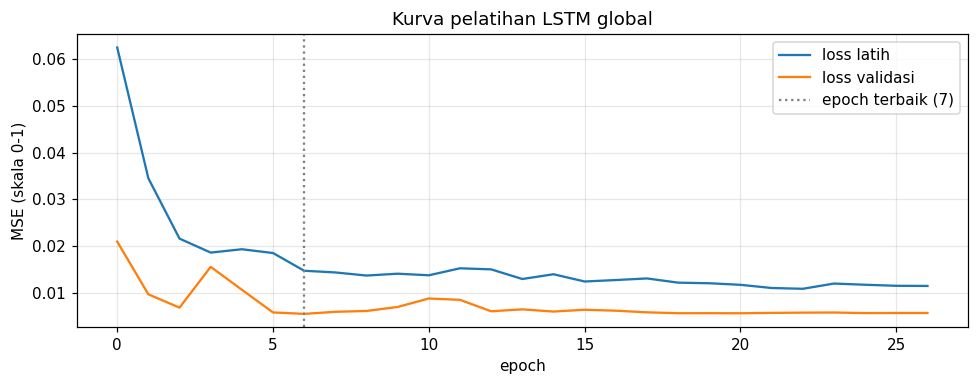

In [20]:
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(history.history["loss"], label="loss latih")
ax.plot(history.history["val_loss"], label="loss validasi")
ax.axvline(best_epoch - 1, ls=":", color="gray", label=f"epoch terbaik ({best_epoch})")
ax.set_title("Kurva pelatihan LSTM global")
ax.set_xlabel("epoch")
ax.set_ylabel("MSE (skala 0-1)")
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "fig_2_lstm_training.png", dpi=120)
plt.show()

In [21]:
def recursive_forecast_lstm(model, scaler, history, start_date, steps, window):
    windows = {}
    for outlet in outlets:
        values = history[history.outlet_id == outlet].sort_values("date")[TARGET].to_numpy(dtype=float)
        scaled_values = scaler.transform(values.reshape(-1, 1)).ravel()
        windows[outlet] = list(scaled_values[-window:])

    one_hot = np.eye(len(outlets))

    collected = []
    for step in range(steps):
        target_date = pd.Timestamp(start_date) + pd.Timedelta(days=step)
        batch_sequence = np.array([windows[outlet][-window:] for outlet in outlets], dtype=float)[..., None]
        batch_outlet = one_hot.copy()

        predictions = model.predict({"sequence": batch_sequence, "outlet": batch_outlet}, verbose=0).ravel()
        for index, outlet in enumerate(outlets):
            windows[outlet].append(float(predictions[index]))
            collected.append({"date": target_date, "outlet_id": outlet, "scaled": float(predictions[index])})

    forecast = pd.DataFrame(collected)
    forecast["prediction"] = scaler.inverse_transform(forecast[["scaled"]].to_numpy()).ravel()
    return forecast[["date", "outlet_id", "prediction"]]


forecast_lstm = recursive_forecast_lstm(lstm_model, scaler, hist_panel, test_dates[0], TEST_DAYS, WINDOW)

forecasts["LSTM Global"] = forecast_lstm
families["LSTM Global"] = "dl"

print("tujuh prediksi total pertama (rupiah):",
      np.round(forecast_lstm.groupby("date").prediction.sum().to_numpy()[:7]).astype(int).tolist())

tujuh prediksi total pertama (rupiah): [4217239, 4228218, 4237260, 4244731, 4250437, 4254885, 4258355]


## 10. Evaluasi gabungan

Semua model dievaluasi pada 28 hari yang sama dengan metrik seragam:

- **MAE**, **RMSE** dalam rupiah;
- **MAPE**, **sMAPE** dalam persen;
- **bias** = rata-rata (prediksi - aktual), untuk melihat kecenderungan over/under-prediksi.

In [22]:
actual_test = test_panel[["date", "outlet_id", TARGET]].rename(columns={TARGET: "actual"})


def score(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    error = actual - predicted
    return {
        "MAE": float(np.mean(np.abs(error))),
        "RMSE": float(np.sqrt(np.mean(error ** 2))),
        "MAPE_%": float(np.mean(np.abs(error) / actual) * 100),
        "sMAPE_%": float(np.mean(2 * np.abs(error) / (np.abs(actual) + np.abs(predicted))) * 100),
        "bias": float(np.mean(predicted - actual)),
    }


actual_total = actual_test.groupby("date").actual.sum()

evaluation_rows = []
for name, forecast in forecasts.items():
    merged = actual_test.merge(forecast, on=ID_COLUMNS, how="inner")
    predicted_total = merged.groupby("date").prediction.sum()
    evaluation_rows.append({"model": name, "family": families[name], **score(actual_total, predicted_total)})

comparison = pd.DataFrame(evaluation_rows).sort_values("MAE").reset_index(drop=True)
best_name = comparison.loc[0, "model"]

print("Perbandingan model pada 28 hari data uji (total semua outlet):")
print(comparison.round(2).to_string(index=False))
print()
print(f"model terbaik: {best_name} (keluarga: {families[best_name]})")

Perbandingan model pada 28 hari data uji (total semua outlet):
                   model   family       MAE      RMSE  MAPE_%  sMAPE_%      bias
Gradient Boosting Global       ml 203115.30 268753.27    4.97     4.98  18927.48
         CatBoost Global       ml 229073.93 293508.45    5.63     5.61  44981.82
          XGBoost Global       ml 235818.88 310811.63    5.88     5.77  82970.78
         LightGBM Global       ml 270071.19 339473.23    6.79     6.57 157950.35
                     ETS     stat 295156.15 371250.97    7.44     7.17 201396.52
             LSTM Global       dl 295252.63 363854.40    7.49     7.18 216549.39
                  SARIMA     stat 330877.11 415601.88    8.30     7.93 224217.19
                 Naive-7 baseline 520978.12 630538.65   12.91    12.40 191763.19

model terbaik: Gradient Boosting Global (keluarga: ml)


In [23]:
per_outlet_rows = []
for name, forecast in forecasts.items():
    merged = actual_test.merge(forecast, on=ID_COLUMNS, how="inner")
    for outlet in outlets:
        subset = merged[merged.outlet_id == outlet]
        per_outlet_rows.append({
            "model": name,
            "family": families[name],
            "outlet_id": outlet,
            **score(subset.actual, subset.prediction),
        })

metrics_per_outlet = pd.DataFrame(per_outlet_rows)

pivot_mae = metrics_per_outlet.pivot(index="model", columns="outlet_id", values="MAE").loc[comparison.model]
pivot_mape = metrics_per_outlet.pivot(index="model", columns="outlet_id", values="MAPE_%").loc[comparison.model]

print("MAE per outlet (rupiah):")
print(pivot_mae.round(0).to_string())
print()
print("MAPE per outlet (persen):")
print(pivot_mape.round(2).to_string())

MAE per outlet (rupiah):
outlet_id                  SHOP001   SHOP002   SHOP003
model                                                 
Gradient Boosting Global  207915.0  137011.0  153864.0
CatBoost Global           193910.0  131120.0  153923.0
XGBoost Global            221740.0  134976.0  148384.0
LightGBM Global           205837.0  165484.0  148807.0
ETS                       241110.0  140807.0  174990.0
LSTM Global               239983.0  137099.0  183534.0
SARIMA                    360661.0  188941.0  156603.0
Naive-7                   378089.0  170335.0  198552.0

MAPE per outlet (persen):
outlet_id                 SHOP001  SHOP002  SHOP003
model                                              
Gradient Boosting Global    11.51    17.43    11.41
CatBoost Global             10.41    17.50    12.06
XGBoost Global              12.28    18.14    11.16
LightGBM Global             11.43    22.80    11.50
ETS                         13.35    17.96    14.17
LSTM Global                 13.34 

In [24]:
family_summary = (
    comparison.groupby("family")
    .agg(model_terbaik=("model", "first"), MAE_terkecil=("MAE", "min"), rata_rata_MAE=("MAE", "mean"))
    .reindex(["stat", "ml", "dl", "baseline"])
    .dropna()
)

print("Ringkasan per keluarga model:")
print(family_summary.round(2).to_string())

Ringkasan per keluarga model:
                     model_terbaik  MAE_terkecil  rata_rata_MAE
family                                                         
stat                           ETS     295156.15      313016.63
ml        Gradient Boosting Global     203115.30      234519.82
dl                     LSTM Global     295252.63      295252.63
baseline                   Naive-7     520978.12      520978.12


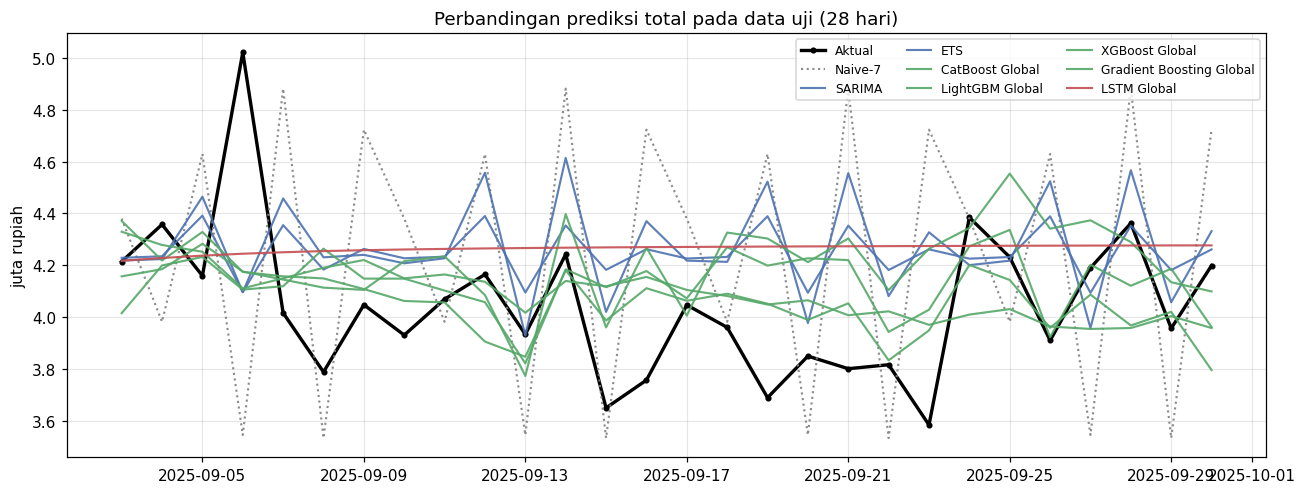

In [25]:
fig, ax = plt.subplots(figsize=(12, 4.6))
ax.plot(actual_total.index, actual_total / 1e6, color="black", lw=2.2, marker="o", ms=3, label="Aktual")

colors = {"stat": "#4c72b0", "ml": "#55a868", "dl": "#c44e52", "baseline": "gray"}
for name, forecast in forecasts.items():
    series = forecast.groupby("date").prediction.sum().reindex(actual_total.index)
    style = ":" if name == "Naive-7" else "-"
    ax.plot(series.index, series / 1e6, ls=style, lw=1.4, color=colors[families[name]], label=name, alpha=0.9)

ax.set_title("Perbandingan prediksi total pada data uji (28 hari)")
ax.set_ylabel("juta rupiah")
ax.legend(ncol=3, fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "fig_3_test_forecast.png", dpi=120)
plt.show()

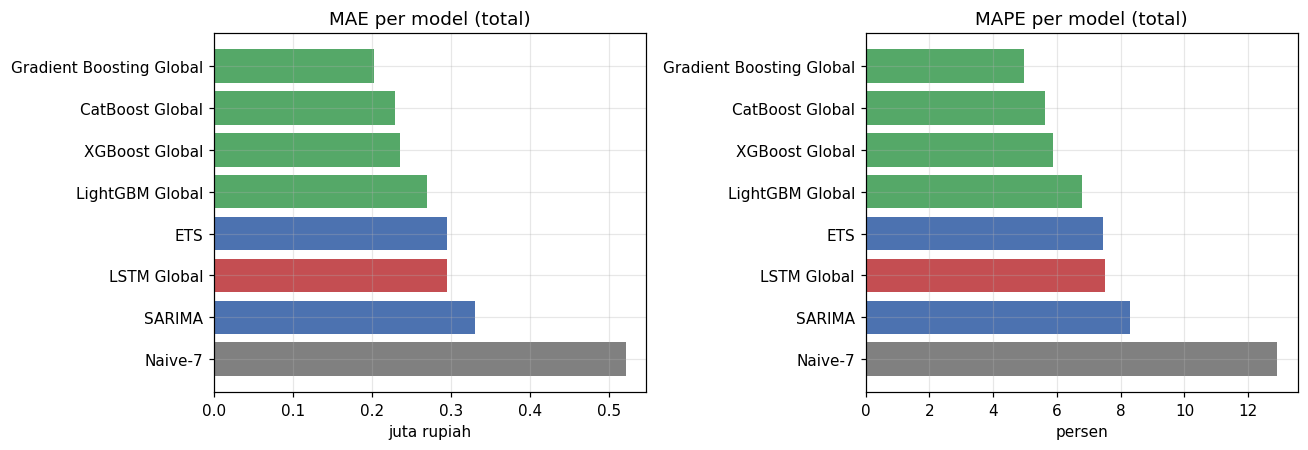

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ordered = comparison.sort_values("MAE", ascending=False)

colors_bar = [colors[family] for family in ordered.family]

axes[0].barh(ordered.model, ordered.MAE / 1e6, color=colors_bar)
axes[0].set_title("MAE per model (total)")
axes[0].set_xlabel("juta rupiah")

axes[1].barh(ordered.model, ordered["MAPE_%"], color=colors_bar)
axes[1].set_title("MAPE per model (total)")
axes[1].set_xlabel("persen")

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "fig_4_metrics.png", dpi=120)
plt.show()

## 11. Feature importance

Kontribusi fitur dari model ML global menunjukkan seberapa besar model bergantung pada histori outlet (`lag`, `roll`) dibanding pola kalender dan identitas outlet.

In [27]:
catboost_importance = pd.Series(
    catboost_model.get_feature_importance(), index=catboost_model.feature_names_
).sort_values(ascending=False)

lgbm_importance = pd.Series(
    lgbm_model.feature_importances_, index=FEATURES
).sort_values(ascending=False)

print("CatBoost - sepuluh fitur paling berpengaruh:")
print(catboost_importance.head(10).round(3).to_string())
print()
print("LightGBM - sepuluh fitur paling berpengaruh:")
print(lgbm_importance.head(10).round(0).to_string())

CatBoost - sepuluh fitur paling berpengaruh:
roll_mean_7     26.332
lag_1           22.010
roll_mean_14    16.965
lag_14           7.648
roll_mean_28     7.639
lag_28           3.580
roll_std_28      3.031
roll_std_7       2.033
lag_7            1.938
outlet_id        1.830

LightGBM - sepuluh fitur paling berpengaruh:
lag_1           2202
lag_28          1840
lag_14          1831
roll_std_7      1795
lag_7           1690
day             1537
roll_std_14     1480
roll_std_28     1306
roll_mean_7     1296
roll_mean_14    1217


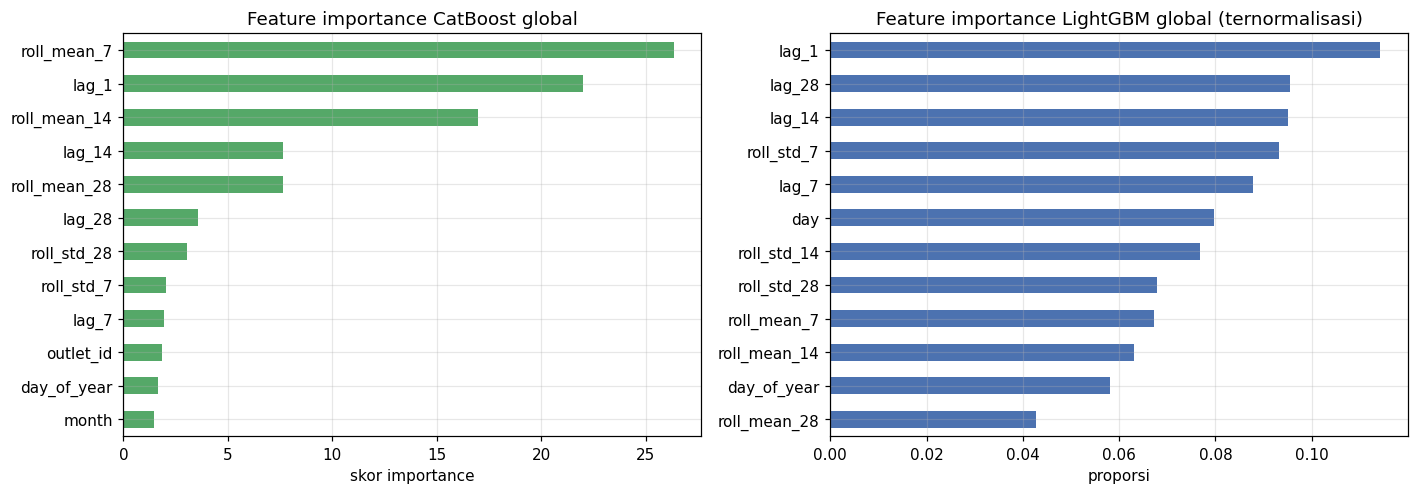

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

catboost_importance.head(12).sort_values().plot(kind="barh", ax=axes[0], color="#55a868")
axes[0].set_title("Feature importance CatBoost global")
axes[0].set_xlabel("skor importance")

(lgbm_importance.head(12) / lgbm_importance.sum()).sort_values().plot(kind="barh", ax=axes[1], color="#4c72b0")
axes[1].set_title("Feature importance LightGBM global (ternormalisasi)")
axes[1].set_xlabel("proporsi")

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "fig_5_feature_importance.png", dpi=120)
plt.show()

## 12. Analisis residual

Residual = aktual - prediksi, dihitung untuk model terbaik. Yang dicari: apakah error tersebar merata, hari apa yang sistematis meleset, dan outlet mana yang paling sulit diprediksi.

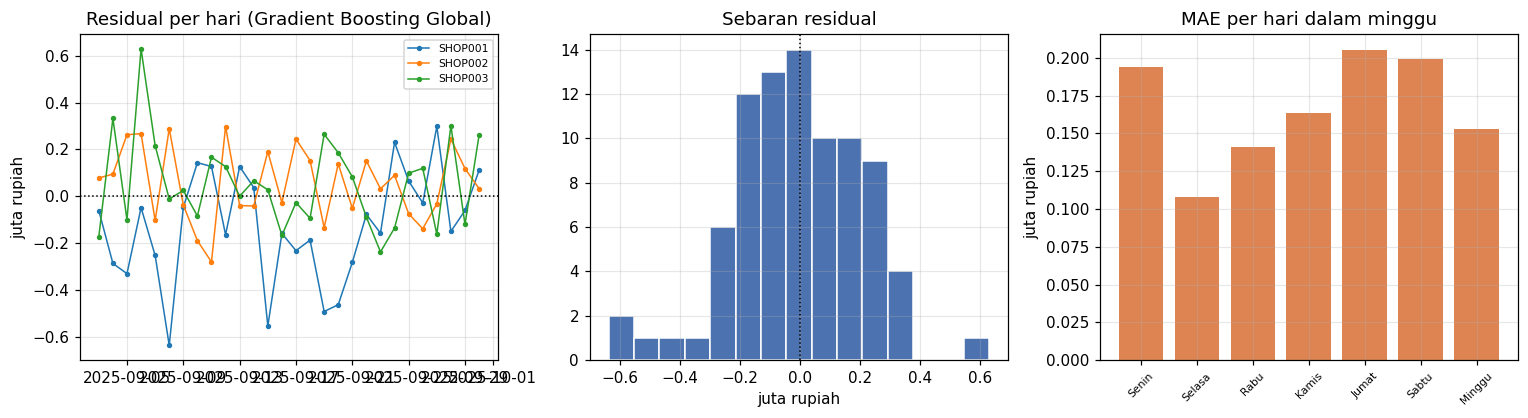

ringkasan residual per outlet (rupiah):
               mean       std       min       max
outlet_id                                        
SHOP001   -126681.0  234227.0 -637724.0  298218.0
SHOP002     54458.0  157207.0 -281037.0  297814.0
SHOP003     53296.0  194927.0 -238250.0  629175.0


In [29]:
best_forecast = forecasts[best_name]
residual_frame = actual_test.merge(best_forecast, on=ID_COLUMNS, how="inner")
residual_frame["error"] = residual_frame.actual - residual_frame.prediction
residual_frame["abs_error"] = residual_frame.error.abs()
residual_frame["dow"] = residual_frame.date.dt.dayofweek

error_by_dow = residual_frame.groupby("dow").abs_error.mean() / 1e6
error_by_dow.index = ["Senin", "Selasa", "Rabu", "Kamis", "Jumat", "Sabtu", "Minggu"]

fig, axes = plt.subplots(1, 3, figsize=(14, 3.9))

for index, outlet in enumerate(outlets):
    subset = residual_frame[residual_frame.outlet_id == outlet]
    axes[0].plot(subset.date, subset.error / 1e6, marker="o", ms=2.5, lw=1,
                 label=outlet, color=palette[index % len(palette)])
axes[0].axhline(0, color="black", lw=1, ls=":")
axes[0].set_title(f"Residual per hari ({best_name})")
axes[0].set_ylabel("juta rupiah")
axes[0].legend(fontsize=7)

axes[1].hist(residual_frame.error / 1e6, bins=15, color="#4c72b0", edgecolor="white")
axes[1].axvline(0, color="black", lw=1, ls=":")
axes[1].set_title("Sebaran residual")
axes[1].set_xlabel("juta rupiah")

axes[2].bar(error_by_dow.index, error_by_dow.values, color="#dd8452")
axes[2].set_title("MAE per hari dalam minggu")
axes[2].set_ylabel("juta rupiah")
axes[2].tick_params(axis="x", rotation=45, labelsize=7)

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "fig_6_residuals.png", dpi=120)
plt.show()

print("ringkasan residual per outlet (rupiah):")
print(residual_frame.groupby("outlet_id").error.agg(["mean", "std", "min", "max"]).round(0).to_string())

## 13. Melatih ulang model terbaik pada seluruh data dan menyimpan model

Model terbaik dilatih ulang memakai **seluruh 272 hari**, sehingga siap meramal 7 hari setelah 30 September 2025.

Disimpan:

- `model.pkl` — bundel berisi konfigurasi, model, dan riwayat yang dibutuhkan untuk peramalan rekursif;
- `model.keras` + `scaler.pkl` bila model terbaik berasal dari blok DL;
- `metadata.json`, tabel prediksi/metrik, dan seluruh grafik.

In [30]:
full_panel = panel
full_total = total_daily


def retrain_stat(name):
    models, config = {}, {}
    for outlet in outlets:
        series = outlet_series(full_panel, outlet)
        if name == "SARIMA":
            order = sarima_config[outlet]["order"]
            seasonal = sarima_config[outlet]["seasonal_order"]
            models[outlet] = SARIMAX(
                series, order=order, seasonal_order=seasonal,
                enforce_stationarity=False, enforce_invertibility=False,
            ).fit(disp=False)
            config[outlet] = {"order": list(order), "seasonal_order": list(seasonal)}
        else:
            models[outlet] = ETSModel(
                series, error="add", trend="add", damped_trend=True,
                seasonal="add", seasonal_periods=SEASON_LENGTH,
            ).fit(disp=False)
            config[outlet] = {"error": "add", "trend": "add damped",
                              "seasonal": "add", "seasonal_periods": SEASON_LENGTH}
    return {"family": "stat", "kind": name, "models": models, "config": config,
            "outlets": outlets, "horizon_days": HORIZON_DAYS, "last_date": full_panel.date.max()}


if best_name in ("SARIMA", "ETS"):
    bundle = retrain_stat(best_name)
elif best_name == "CatBoost Global":
    final_model = CatBoostRegressor(**CATBOOST_CONFIG, l2_leaf_reg=3.0, eval_metric="MAE",
                                    random_seed=SEED, verbose=False, allow_writing_files=False)
    final_model.fit(Pool(full_df[FEATURES], full_df[TARGET], cat_features=CAT_FEATURES))
    bundle = {"family": "ml", "kind": best_name, "obj": final_model, "features": FEATURES,
              "cat_features": CAT_FEATURES, "history": full_panel[["date", "outlet_id", TARGET]].copy(),
              "outlets": outlets, "horizon_days": HORIZON_DAYS, "last_date": full_panel.date.max()}
elif best_name == "LightGBM Global":
    final_model = LGBMRegressor(n_estimators=800, learning_rate=0.03, num_leaves=31,
                                subsample=0.9, colsample_bytree=0.9, random_state=SEED, verbose=-1)
    final_model.fit(categorical_frame(full_df), full_df[TARGET])
    bundle = {"family": "ml", "kind": best_name, "obj": final_model, "features": FEATURES,
              "encoding": "category", "history": full_panel[["date", "outlet_id", TARGET]].copy(),
              "outlets": outlets, "horizon_days": HORIZON_DAYS, "last_date": full_panel.date.max()}
elif best_name == "XGBoost Global":
    final_model = XGBRegressor(n_estimators=800, learning_rate=0.03, max_depth=4, subsample=0.9,
                               colsample_bytree=0.9, tree_method="hist", enable_categorical=True,
                               random_state=SEED)
    final_model.fit(categorical_frame(full_df), full_df[TARGET])
    bundle = {"family": "ml", "kind": best_name, "obj": final_model, "features": FEATURES,
              "encoding": "category", "history": full_panel[["date", "outlet_id", TARGET]].copy(),
              "outlets": outlets, "horizon_days": HORIZON_DAYS, "last_date": full_panel.date.max()}
elif best_name == "Gradient Boosting Global":
    final_model = GradientBoostingRegressor(n_estimators=400, learning_rate=0.05, max_depth=3,
                                            subsample=0.9, random_state=SEED)
    final_model.fit(numeric_frame(full_df), full_df[TARGET])
    bundle = {"family": "ml", "kind": best_name, "obj": final_model, "features": FEATURES,
              "encoding": "code", "history": full_panel[["date", "outlet_id", TARGET]].copy(),
              "outlets": outlets, "horizon_days": HORIZON_DAYS, "last_date": full_panel.date.max()}
else:
    full_scaler = MinMaxScaler(feature_range=(0, 1))
    full_scaler.fit(full_panel[[TARGET]].to_numpy(dtype=float))
    scaler = full_scaler

    full_scaled = scaled_panel(full_panel)
    X_full_seq, X_full_id, y_full_seq, _ = build_sequences(full_scaled, WINDOW)

    final_model = build_lstm(WINDOW, len(outlets))
    final_model.fit({"sequence": X_full_seq, "outlet": X_full_id}, y_full_seq,
                    epochs=best_epoch, batch_size=BATCH_SIZE, shuffle=False, verbose=0)

    KERAS_PATH = OUTPUT_DIR / "model.keras"
    SCALER_PATH = OUTPUT_DIR / "scaler.pkl"
    final_model.save(KERAS_PATH)
    with open(SCALER_PATH, "wb") as file:
        pickle.dump(full_scaler, file, protocol=pickle.HIGHEST_PROTOCOL)

    bundle = {"family": "dl", "kind": "LSTM Global", "model_file": KERAS_PATH.name,
              "scaler_file": SCALER_PATH.name, "window": WINDOW, "history": full_panel[["date", "outlet_id", TARGET]].copy(),
              "outlets": outlets, "horizon_days": HORIZON_DAYS, "last_date": full_panel.date.max()}

bundle["name"] = best_name
bundle["family"] = bundle["family"]
bundle["mae_test"] = float(comparison.loc[0, "MAE"])
bundle["trained_on_days"] = int(full_panel.date.nunique())

with open(BUNDLE_PATH, "wb") as file:
    pickle.dump(bundle, file, protocol=pickle.HIGHEST_PROTOCOL)

print(f"model terbaik        : {best_name} ({bundle['family']})")
print(f"dilatih ulang pada   : {bundle['trained_on_days']} hari")
print(f"bundel tersimpan     : {BUNDLE_PATH.name} ({BUNDLE_PATH.stat().st_size / 1024:,.1f} KB)")
for path in sorted(OUTPUT_DIR.glob("model.*")):
    print(f"  {path.name:<24} {path.stat().st_size / 1024:>9.1f} KB")

model terbaik        : Gradient Boosting Global (ml)
dilatih ulang pada   : 272 hari
bundel tersimpan     : model.pkl (530.5 KB)
  model.pkl                    530.5 KB


In [31]:
def forecast_with_bundle(bundle, steps, start_date=None):
    family = bundle["family"]
    start = pd.Timestamp(start_date) if start_date is not None else bundle["last_date"] + pd.Timedelta(days=1)
    dates = pd.date_range(start, periods=steps, freq="D")

    if family == "stat":
        frames = []
        for outlet, model in bundle["models"].items():
            values = model.forecast(steps) if hasattr(model, "forecast") else model.predict(steps)
            frames.append(pd.DataFrame({"date": dates, "outlet_id": outlet,
                                        "prediction": np.asarray(values, dtype=float)}))
        return pd.concat(frames, ignore_index=True)

    if family == "ml":
        model = bundle["obj"]
        if bundle.get("encoding") == "category":
            predict_fn = lambda frame: model.predict(categorical_frame(frame))
        elif bundle.get("encoding") == "code":
            predict_fn = lambda frame: model.predict(numeric_frame(frame))
        else:
            predict_fn = lambda frame: model.predict(frame[FEATURES])
        return recursive_forecast_ml(predict_fn, bundle["history"], dates[0], steps)

    model = keras.models.load_model(OUTPUT_DIR / bundle["model_file"], compile=False)
    with open(OUTPUT_DIR / bundle["scaler_file"], "rb") as file:
        loaded_scaler = pickle.load(file)
    return recursive_forecast_lstm(model, loaded_scaler, bundle["history"], dates[0], steps, bundle["window"])


with open(BUNDLE_PATH, "rb") as file:
    reloaded = pickle.load(file)

future_dates = pd.date_range(panel.date.max() + pd.Timedelta(days=1), periods=HORIZON_DAYS, freq="D")
forecast_future = forecast_with_bundle(reloaded, HORIZON_DAYS)
future_wide = forecast_future.pivot(index="date", columns="outlet_id", values="prediction")
future_wide["TOTAL"] = future_wide.sum(axis=1)

print(f"model dimuat : {reloaded['name']} ({reloaded['family']})")
print(f"data terakhir: {reloaded['last_date'].date()}")
print()
print("ramalan 7 hari ke depan (rupiah):")
print(future_wide.round(0).to_string())

model dimuat : Gradient Boosting Global (ml)
data terakhir: 2025-09-30

ramalan 7 hari ke depan (rupiah):
outlet_id     SHOP001   SHOP002    SHOP003      TOTAL
date                                                 
2025-10-01  1911702.0  758902.0  1334673.0  4005277.0
2025-10-02  2071806.0  746821.0  1379430.0  4198058.0
2025-10-03  2001672.0  771107.0  1275301.0  4048080.0
2025-10-04  2015565.0  761766.0  1381288.0  4158618.0
2025-10-05  2069027.0  815513.0  1324186.0  4208726.0
2025-10-06  2151969.0  782936.0  1255202.0  4190107.0
2025-10-07  2042289.0  772989.0  1201301.0  4016579.0


## 14. Metadata dan tabel hasil

Seluruh konfigurasi dan hasil evaluasi dicatat di `metadata.json` agar satu folder artefak bisa dipindah tanpa kehilangan konteks.

In [32]:
extra_model_files = [name for name in ("model.keras", "scaler.pkl") if (OUTPUT_DIR / name).exists()]

metadata = {
    "project": "MyVentory sales forecasting",
    "notebook": "sales_forecast_exp",
    "target": "NetSales harian per outlet",
    "granularity": "harian x outlet",
    "environment": f"conda Machine-Learning (python {sys.version.split()[0]})",
    "source": {
        "file": "data/Transactions.csv",
        "outlets": outlets,
        "rows": int(len(transactions)),
    },
    "period": {
        "start": str(panel.date.min().date()),
        "end": str(panel.date.max().date()),
        "days": int(panel.date.nunique()),
    },
    "split": {
        "train": [str(pd.Timestamp(train_dates.min()).date()), str(pd.Timestamp(train_dates.max()).date())],
        "validation": [str(pd.Timestamp(val_dates.min()).date()), str(pd.Timestamp(val_dates.max()).date())],
        "test": [str(pd.Timestamp(test_dates.min()).date()), str(pd.Timestamp(test_dates.max()).date())],
        "train_days": int(len(train_dates)),
        "validation_days": int(len(val_dates)),
        "test_days": int(len(test_dates)),
    },
    "seasonality": {
        "season_length_days": SEASON_LENGTH,
        "stl_strength": round(float(strength), 4),
    },
    "features": FEATURES,
    "config": {
        "stat": {
            "SARIMA": {outlet: config for outlet, config in sarima_config.items()},
            "ETS": {outlet: config for outlet, config in ets_config.items()},
        },
        "ml": {
            "CatBoost Global": {**CATBOOST_CONFIG, "l2_leaf_reg": 3.0, "eval_metric": "MAE", "random_seed": SEED},
            "LightGBM Global": {"n_estimators": 800, "learning_rate": 0.03, "num_leaves": 31},
            "XGBoost Global": {"n_estimators": 800, "learning_rate": 0.03, "max_depth": 4},
            "Gradient Boosting Global": {"n_estimators": 400, "learning_rate": 0.05, "max_depth": 3},
        },
        "dl": {
            "LSTM Global": {
                "window": WINDOW,
                "layers": ["LSTM 64 (return_sequences)", "Dropout 0.2", "LSTM 32",
                           "Dense 16 outlet embedding", "Concat", "Dropout 0.2", "Dense 16 relu", "Dense 1"],
                "optimizer": "Adam 1e-3",
                "loss": "mse",
                "batch_size": BATCH_SIZE,
                "epochs_trained": int(best_epoch),
                "scaler": "MinMaxScaler 0-1 (fit pada train)",
                "random_state": SEED,
            },
        },
    },
    "metrics": {
        record["model"]: {
            "family": record["family"],
            **{key: round(float(record[key]), 2) for key in ["MAE", "RMSE", "MAPE_%", "sMAPE_%", "bias"]},
        }
        for record in comparison.to_dict(orient="records")
    },
    "best_model": {
        "name": best_name,
        "family": families[best_name],
        "file": BUNDLE_PATH.name,
        "trained_on_days": int(full_panel.date.nunique()),
        "last_date": str(panel.date.max().date()),
        "horizon_days": HORIZON_DAYS,
        "mae_test": round(float(comparison.loc[0, "MAE"]), 2),
    },
    "artifacts": [BUNDLE_PATH.name, *extra_model_files, METADATA_PATH.name,
        "sales_forecast_exp_daily.csv",
        "sales_forecast_exp_comparison.csv",
        "sales_forecast_exp_per_outlet.csv",
        "sales_forecast_exp_future.csv",
        "fig_1_series.png",
        "fig_2_lstm_training.png",
        "fig_3_test_forecast.png",
        "fig_4_metrics.png",
        "fig_5_feature_importance.png",
        "fig_6_residuals.png",
    ],
}

METADATA_PATH.write_text(json.dumps(metadata, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
print("metadata tersimpan:", METADATA_PATH)
print(json.dumps(metadata["best_model"], indent=2, ensure_ascii=False))

metadata tersimpan: ..\artifacts\sales_forecast_exp\metadata.json
{
  "name": "Gradient Boosting Global",
  "family": "ml",
  "file": "model.pkl",
  "trained_on_days": 272,
  "last_date": "2025-09-30",
  "horizon_days": 7,
  "mae_test": 203115.3
}


In [33]:
test_wide = pd.DataFrame({"aktual": actual_test.groupby("date").actual.sum()})
for name, forecast in forecasts.items():
    test_wide[name] = forecast.groupby("date").prediction.sum().reindex(test_wide.index)

test_wide.index.name = "tanggal"
test_wide.reset_index().to_csv(OUTPUT_DIR / "sales_forecast_exp_daily.csv", index=False)
comparison.to_csv(OUTPUT_DIR / "sales_forecast_exp_comparison.csv", index=False)
metrics_per_outlet.to_csv(OUTPUT_DIR / "sales_forecast_exp_per_outlet.csv", index=False)
forecast_future.to_csv(OUTPUT_DIR / "sales_forecast_exp_future.csv", index=False)

print(f"isi folder {OUTPUT_DIR.resolve()}:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print(f"  {path.name:<42} {path.stat().st_size / 1024:>9.1f} KB")

isi folder C:\Users\Radit\Politeknik Negeri Malang\Semester 5\ProjectBasedLearning_MyVentory\ML\artifacts\sales_forecast_exp:
  fig_1_series.png                               259.5 KB
  fig_2_lstm_training.png                         42.4 KB
  fig_3_test_forecast.png                        211.0 KB
  fig_4_metrics.png                               33.5 KB
  fig_5_feature_importance.png                    51.7 KB
  fig_6_residuals.png                            105.3 KB
  metadata.json                                    5.7 KB
  model.pkl                                      530.5 KB
  sales_forecast_exp_comparison.csv                0.9 KB
  sales_forecast_exp_daily.csv                     4.4 KB
  sales_forecast_exp_future.csv                    0.8 KB
  sales_forecast_exp_per_outlet.csv                2.9 KB


## 15. Verifikasi berkas model

Bundel dimuat ulang dari disk tanpa memakai variabel notebook, lalu dipakai meramal 7 hari setelah 30 September 2025.

In [34]:
with open(BUNDLE_PATH, "rb") as file:
    verification_bundle = pickle.load(file)

verification_forecast = forecast_with_bundle(verification_bundle, HORIZON_DAYS)
verification_wide = verification_forecast.pivot(index="date", columns="outlet_id", values="prediction")
verification_wide["TOTAL"] = verification_wide.sum(axis=1)

print("berkas         :", BUNDLE_PATH.name)
print("model          :", verification_bundle["name"], f"({verification_bundle['family']})")
print("data terakhir  :", verification_bundle["last_date"].date())
print("periode ramalan:", verification_wide.index.min().date(), "s/d", verification_wide.index.max().date())
print()
print(verification_wide.round(0).to_string())
print()
print(f"total 7 hari   : Rp {verification_wide['TOTAL'].sum():,.0f}")

berkas         : model.pkl
model          : Gradient Boosting Global (ml)
data terakhir  : 2025-09-30
periode ramalan: 2025-10-01 s/d 2025-10-07

outlet_id     SHOP001   SHOP002    SHOP003      TOTAL
date                                                 
2025-10-01  1911702.0  758902.0  1334673.0  4005277.0
2025-10-02  2071806.0  746821.0  1379430.0  4198058.0
2025-10-03  2001672.0  771107.0  1275301.0  4048080.0
2025-10-04  2015565.0  761766.0  1381288.0  4158618.0
2025-10-05  2069027.0  815513.0  1324186.0  4208726.0
2025-10-06  2151969.0  782936.0  1255202.0  4190107.0
2025-10-07  2042289.0  772989.0  1201301.0  4016579.0

total 7 hari   : Rp 28,825,445


## 16. Ringkasan

In [35]:
print("RINGKASAN EKSPERIMEN")
print("=" * 74)
print("target        : NetSales harian per outlet")
print(f"periode data  : {panel.date.min().date()} s/d {panel.date.max().date()} ({panel.date.nunique()} hari x {len(outlets)} outlet)")
print(f"split         : train {len(train_dates)} hari | validation {len(val_dates)} hari | test {len(test_dates)} hari")
print(f"kekuatan pola mingguan (STL): {strength:.3f}")
print()
print("HASIL PER KELUARGA MODEL")
print("-" * 74)
print(family_summary.round(2).to_string())
print()
print("PERBANDINGAN SEMUA MODEL")
print("-" * 74)
print(comparison[["model", "family", "MAE", "RMSE", "MAPE_%", "sMAPE_%", "bias"]].round(2).to_string(index=False))
print()
print(f"MODEL TERBAIK : {best_name} ({families[best_name]})")
print(f"MAE           : Rp {comparison.loc[0, 'MAE']:,.0f}")
print(f"MAPE          : {comparison.loc[0, 'MAPE_%']:.2f}%")
print()
print("catatan : blok A (statistik) dilatih per outlet, blok B dan C dilatih sebagai satu model global.")

RINGKASAN EKSPERIMEN
target        : NetSales harian per outlet
periode data  : 2025-01-02 s/d 2025-09-30 (272 hari x 3 outlet)
split         : train 216 hari | validation 28 hari | test 28 hari
kekuatan pola mingguan (STL): 0.770

HASIL PER KELUARGA MODEL
--------------------------------------------------------------------------
                     model_terbaik  MAE_terkecil  rata_rata_MAE
family                                                         
stat                           ETS     295156.15      313016.63
ml        Gradient Boosting Global     203115.30      234519.82
dl                     LSTM Global     295252.63      295252.63
baseline                   Naive-7     520978.12      520978.12

PERBANDINGAN SEMUA MODEL
--------------------------------------------------------------------------
                   model   family       MAE      RMSE  MAPE_%  sMAPE_%      bias
Gradient Boosting Global       ml 203115.30 268753.27    4.97     4.98  18927.48
         CatBoost Glo

## 17. Export model ke API (berversion)

Model terbaik dan metadata disalin ke `API/artifacts/sales_forecast_exp/1.0.0/`.

In [36]:
import shutil

NOTEBOOK_NAME = "sales_forecast_exp"
NOTEBOOK_VERSION = "1.0.0"
API_DIR = Path("..").resolve().parent / "API" / "artifacts" / NOTEBOOK_NAME / NOTEBOOK_VERSION
API_DIR.mkdir(parents=True, exist_ok=True)

api_metadata = json.loads(METADATA_PATH.read_text(encoding="utf-8"))
api_metadata.update({
    "model_id": NOTEBOOK_NAME,
    "model_version": NOTEBOOK_VERSION,
    "source_notebook": NOTEBOOK_NAME,
})

copied = [BUNDLE_PATH]
for extra in ["model.keras", "scaler.pkl"]:
    if (OUTPUT_DIR / extra).exists():
        copied.append(OUTPUT_DIR / extra)
for path in copied:
    shutil.copy2(path, API_DIR / path.name)
(API_DIR / "metadata.json").write_text(
    json.dumps(api_metadata, indent=2, ensure_ascii=False) + "\n",
    encoding="utf-8",
)

print(f"{NOTEBOOK_NAME} versi {NOTEBOOK_VERSION} diekspor ke:")
print(" ", API_DIR)
for path in sorted(API_DIR.iterdir()):
    print(f"   {path.name:<20} {path.stat().st_size / 1024:>9.1f} KB")

sales_forecast_exp versi 1.0.0 diekspor ke:
  C:\Users\Radit\Politeknik Negeri Malang\Semester 5\ProjectBasedLearning_MyVentory\API\artifacts\sales_forecast_exp\1.0.0
   metadata.json              5.8 KB
   model.pkl                530.5 KB


## 18. Eksperimen Perbandingan Model Global (8 Metode)

Bagian ini menambahkan eksperimen pembanding yang **terpisah dari hasil asli di atas**. Seluruh keluaran asli (`artifacts/sales_forecast_exp/`) tidak ditimpa; hasil pembanding disimpan di `artifacts/sales_forecast_exp_comparison/`.

**Delapan metode yang dibandingkan:**

| Keluarga | Model | Strategi |
|---|---|---|
| Baseline | Naive | per outlet, `y(t) = y(t-1)` (persistence) |
| Baseline | Seasonal Naive (7) | per outlet, `y(t) = y(t-7)` |
| Machine Learning | Gradient Boosting Global | satu model global, `outlet_id` numerik |
| Machine Learning | CatBoost Global | satu model global, `outlet_id` kategorikal |
| Machine Learning | XGBoost Global | satu model global, `outlet_id` kategorikal |
| Machine Learning | LightGBM Global | satu model global, `outlet_id` kategorikal |
| Deep Learning | LSTM Global | satu model global, sequence multivariat + one-hot outlet |
| Deep Learning | 1D CNN Global | satu model global, sequence multivariat + one-hot outlet |

**Arsitektur global yang dipakai seragam:**

```
Data gabungan 3 outlet
        |
  pelatihan satu model global per algoritma
        |
   satu model bersama
        |
  peramalan terpisah per outlet (rekursif 28 hari)
   /          |          \
SHOP001    SHOP002    SHOP003
```

**Pengaturan yang dipertahankan dari eksperimen asli:** agregasi harian per outlet, pembersihan data dan panel lengkap, batas split kronologis train/validation/test, fitur lag 1/7/14/28, rolling mean dan std 7/14/28, fitur kalender, `outlet_id`, horizon uji 28 hari, serta peramalan rekursif untuk model ML.

**Inkonsistensi eksperimen asli yang diperbaiki di bagian ini:**

1. Baseline yang diberi nama `Naive-7` sebenarnya adalah **seasonal naive** `y(t) = y(t-7)`, bukan naive `y(t) = y(t-1)`. Di sini keduanya dipisahkan menjadi `Naive` dan `Seasonal Naive (7)`.
2. `MAPE` asli membagi dengan nilai aktual tanpa penanganan nol. Di sini `MAPE` hanya dihitung pada hari dengan aktual tidak nol, `sMAPE` mengabaikan penyebut nol, dan `WAPE` memakai total aktual sebagai penyebut. Jumlah hari nol dilaporkan.
3. `HORIZON_DAYS = 7` pada eksperimen asli adalah horizon produksi (ramalan setelah data terakhir), bukan horizon evaluasi. Evaluasi tetap memakai `TEST_DAYS = 28`; bagian ini memakai `CMP_HORIZON = TEST_DAYS`.
4. LSTM asli memakai sequence univariat (hanya penjualan) ditambah one-hot outlet. Bagian ini memakai sequence **multivariat** (penjualan terskala + 7 kanal one-hot hari + indikator akhir pekan) agar memenuhi kebutuhan model deep learning multivariat, dengan one-hot outlet tetap menjadi input tambahan.
5. Metrik overall asli sudah dihitung dari **agregasi harian seluruh outlet**; prosedur itu dipertahankan dan diperjelas, bukan dirata-ratakan dari MAE per outlet.


### 18.1 Konfigurasi pembanding dan fungsi evaluasi

Semua model memakai periode uji yang sama, horizon 28 hari, target yang sama, dan definisi metrik yang sama. `Bias = mean(prediction - actual)`; nilai positif berarti overforecast.


In [37]:
CMP_DIR = Path("..") / "artifacts" / "sales_forecast_exp_comparison"
CMP_DIR.mkdir(parents=True, exist_ok=True)

CMP_MODELS = [
    ("Naive", "baseline"),
    ("Seasonal Naive (7)", "baseline"),
    ("Gradient Boosting Global", "ml"),
    ("CatBoost Global", "ml"),
    ("XGBoost Global", "ml"),
    ("LightGBM Global", "ml"),
    ("LSTM Global", "dl"),
    ("1D CNN Global", "dl"),
]
CMP_FAMILY = dict(CMP_MODELS)
CMP_LABEL = {"baseline": "Baseline", "ml": "Machine Learning", "dl": "Deep Learning"}
CMP_HORIZON = int(TEST_DAYS)


def cmp_naive_forecast(history, start_dates, season_length=1):
    """Naive (season_length=1) atau seasonal naive per outlet, tanpa melihat data uji."""
    frames = []
    for outlet in outlets:
        values = history[history.outlet_id == outlet].sort_values("date")[TARGET].to_numpy(dtype=float)
        for position, date in enumerate(start_dates):
            if season_length == 1:
                value = values[-1]
            else:
                value = values[-season_length + (position % season_length)]
            frames.append({"date": date, "outlet_id": outlet, "prediction": float(value)})
    return pd.DataFrame(frames)


def cmp_score(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    error = predicted - actual
    abs_error = np.abs(error)
    nonzero = actual != 0
    mape = float(np.mean(abs_error[nonzero] / np.abs(actual[nonzero])) * 100) if nonzero.any() else float("nan")
    denom = np.abs(actual) + np.abs(predicted)
    smape_mask = denom != 0
    smape = float(np.mean(2 * abs_error[smape_mask] / denom[smape_mask]) * 100) if smape_mask.any() else float("nan")
    total_actual = float(np.sum(np.abs(actual)))
    wape = float(abs_error.sum() / total_actual * 100) if total_actual > 0 else float("nan")
    return {
        "MAE": float(np.mean(abs_error)),
        "RMSE": float(np.sqrt(np.mean(error ** 2))),
        "MAPE_%": mape,
        "sMAPE_%": smape,
        "WAPE_%": wape,
        "Bias": float(np.mean(error)),
        "n_obs": int(len(actual)),
        "n_zero_actual": int((~nonzero).sum()),
    }


def cmp_evaluate(forecasts, actual_frame):
    overall_rows, outlet_rows = [], []
    for name, forecast in forecasts.items():
        merged = actual_frame.merge(forecast, on=ID_COLUMNS, how="inner", validate="one_to_one")
        assert len(merged) == len(actual_frame), f"{name}: pasangan tanggal-outlet tidak lengkap"
        daily = merged.groupby("date", as_index=False).agg(
            actual=("actual", "sum"), prediction=("prediction", "sum")
        )
        overall_rows.append({"model": name, "family": CMP_FAMILY[name], **cmp_score(daily.actual, daily.prediction)})
        for outlet in outlets:
            subset = merged[merged.outlet_id == outlet]
            outlet_rows.append({
                "model": name,
                "family": CMP_FAMILY[name],
                "outlet_id": outlet,
                **cmp_score(subset.actual, subset.prediction),
            })
    return pd.DataFrame(overall_rows), pd.DataFrame(outlet_rows)


def cmp_check_coverage(forecasts):
    expected_dates = set(pd.to_datetime(test_dates))
    for name, forecast in forecasts.items():
        assert set(pd.to_datetime(forecast.date)) == expected_dates, f"{name}: tanggal uji tidak sama"
        assert forecast.groupby("outlet_id").size().eq(CMP_HORIZON).all(), f"{name}: horizon per outlet salah"
        assert not forecast.duplicated(ID_COLUMNS).any(), f"{name}: prediksi duplikat"
        assert forecast.prediction.notna().all(), f"{name}: ada prediksi NaN"
        assert (forecast.prediction >= 0).all(), f"{name}: ada prediksi negatif"
    print(f"cek cakupan lolos: {len(forecasts)} model x {len(outlets)} outlet x {CMP_HORIZON} hari")


print("folder pembanding:", CMP_DIR.resolve())
print("horizon evaluasi :", CMP_HORIZON, "hari")
print("model            :", [name for name, _ in CMP_MODELS])


folder pembanding: C:\Users\Radit\Politeknik Negeri Malang\Semester 5\ProjectBasedLearning_MyVentory\ML\artifacts\sales_forecast_exp_comparison
horizon evaluasi : 28 hari
model            : ['Naive', 'Seasonal Naive (7)', 'Gradient Boosting Global', 'CatBoost Global', 'XGBoost Global', 'LightGBM Global', 'LSTM Global', '1D CNN Global']


### 18.2 Baseline: Naive dan Seasonal Naive

Keduanya diterapkan per outlet memakai riwayat train + validation. `Naive` mempertahankan nilai terakhir selama 28 hari; `Seasonal Naive (7)` mengulang pola tujuh hari terakhir.


In [38]:
cmp_forecasts = {}
cmp_forecasts["Naive"] = cmp_naive_forecast(hist_panel, test_dates, season_length=1)
cmp_forecasts["Seasonal Naive (7)"] = cmp_naive_forecast(hist_panel, test_dates, season_length=SEASON_LENGTH)

cmp_check_coverage(cmp_forecasts)

for name, forecast in cmp_forecasts.items():
    total = forecast.groupby("date").prediction.sum()
    print(f"{name:<22} total 28 hari: Rp {total.sum():,.0f}")
print()
print(cmp_forecasts["Naive"].head(6).round(0).to_string(index=False))


cek cakupan lolos: 2 model x 3 outlet x 28 hari
Naive                  total 28 hari: Rp 132,255,857
Seasonal Naive (7)     total 28 hari: Rp 118,702,703

      date outlet_id  prediction
2025-09-03   SHOP001   2463964.0
2025-09-04   SHOP001   2463964.0
2025-09-05   SHOP001   2463964.0
2025-09-06   SHOP001   2463964.0
2025-09-07   SHOP001   2463964.0
2025-09-08   SHOP001   2463964.0


### 18.3 Model machine learning global

Empat algoritma dilatih sebagai **satu model global** pada data gabungan tiga outlet. Matriks fitur identik dengan eksperimen asli (`FEATURES`). `outlet_id` diperlakukan sebagai kategorikal untuk CatBoost, XGBoost, dan LightGBM, serta sebagai kode numerik untuk Gradient Boosting scikit-learn.

Hyperparameter CatBoost dipilih hanya dari data train dan validation; model final dilatih ulang pada train + validation. Algoritma lain memakai hyperparameter tetap yang sama dengan eksperimen asli.


In [39]:
from catboost import CatBoostRegressor, Pool
from lightgbm import LGBMRegressor
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBRegressor

cmp_global_models = {}
cmp_ml_config = {}

# 1. Gradient Boosting (scikit-learn), outlet_id sebagai kode numerik
gbr_model = GradientBoostingRegressor(
    n_estimators=400,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.9,
    random_state=SEED,
)
gbr_model.fit(numeric_frame(trainval_df), trainval_df[TARGET])
cmp_global_models["Gradient Boosting Global"] = gbr_model
cmp_ml_config["Gradient Boosting Global"] = {
    "n_estimators": 400, "learning_rate": 0.05, "max_depth": 3, "subsample": 0.9,
    "encoding": "numeric_code", "trained_on": "train+validation",
}

# 2. CatBoost, outlet_id sebagai fitur kategorikal, tuning pada validation
cmp_cat_grid = []
for loss_function in ["MAE", "RMSE"]:
    for depth in [4, 6]:
        candidate = CatBoostRegressor(
            iterations=2000,
            learning_rate=0.03,
            depth=depth,
            l2_leaf_reg=3.0,
            loss_function=loss_function,
            eval_metric="MAE",
            random_seed=SEED,
            od_type="Iter",
            od_wait=100,
            verbose=False,
            allow_writing_files=False,
        )
        candidate.fit(
            Pool(train_df[FEATURES], train_df[TARGET], cat_features=CAT_FEATURES),
            eval_set=Pool(val_df[FEATURES], val_df[TARGET], cat_features=CAT_FEATURES),
            use_best_model=True,
        )
        cmp_cat_grid.append({
            "loss": loss_function,
            "depth": depth,
            "learning_rate": 0.03,
            "iterations": int(candidate.get_best_iteration()) + 1,
            "val_MAE": float(candidate.get_best_score()["validation"]["MAE"]),
        })

cmp_cat_table = pd.DataFrame(cmp_cat_grid).sort_values("val_MAE").reset_index(drop=True)
cmp_cat_best = cmp_cat_table.loc[0]
cmp_cat_config = {
    "loss_function": str(cmp_cat_best.loss),
    "depth": int(cmp_cat_best.depth),
    "learning_rate": float(cmp_cat_best.learning_rate),
    "iterations": int(cmp_cat_best.iterations),
}
catboost_model = CatBoostRegressor(
    **cmp_cat_config,
    l2_leaf_reg=3.0,
    eval_metric="MAE",
    random_seed=SEED,
    verbose=False,
    allow_writing_files=False,
)
catboost_model.fit(Pool(trainval_df[FEATURES], trainval_df[TARGET], cat_features=CAT_FEATURES))
cmp_global_models["CatBoost Global"] = catboost_model
cmp_ml_config["CatBoost Global"] = {**cmp_cat_config, "encoding": "categorical", "trained_on": "train+validation"}

# 3. XGBoost, outlet_id kategorikal
xgb_model = XGBRegressor(
    n_estimators=800,
    learning_rate=0.03,
    max_depth=4,
    subsample=0.9,
    colsample_bytree=0.9,
    tree_method="hist",
    enable_categorical=True,
    random_state=SEED,
)
xgb_model.fit(categorical_frame(trainval_df), trainval_df[TARGET])
cmp_global_models["XGBoost Global"] = xgb_model
cmp_ml_config["XGBoost Global"] = {
    "n_estimators": 800, "learning_rate": 0.03, "max_depth": 4, "subsample": 0.9,
    "encoding": "categorical", "trained_on": "train+validation",
}

# 4. LightGBM, outlet_id kategorikal
lgbm_model = LGBMRegressor(
    n_estimators=800,
    learning_rate=0.03,
    num_leaves=31,
    subsample=0.9,
    colsample_bytree=0.9,
    random_state=SEED,
    verbose=-1,
)
lgbm_model.fit(categorical_frame(trainval_df), trainval_df[TARGET])
cmp_global_models["LightGBM Global"] = lgbm_model
cmp_ml_config["LightGBM Global"] = {
    "n_estimators": 800, "learning_rate": 0.03, "num_leaves": 31, "subsample": 0.9,
    "encoding": "categorical", "trained_on": "train+validation",
}

# Peramalan rekursif 28 hari dengan satu model global per algoritma
cmp_forecasts["Gradient Boosting Global"] = recursive_forecast_ml(
    lambda frame: gbr_model.predict(numeric_frame(frame)), hist_panel, test_dates[0], CMP_HORIZON
)
cmp_forecasts["CatBoost Global"] = recursive_forecast_ml(
    lambda frame: catboost_model.predict(frame[FEATURES]), hist_panel, test_dates[0], CMP_HORIZON
)
cmp_forecasts["XGBoost Global"] = recursive_forecast_ml(
    lambda frame: xgb_model.predict(categorical_frame(frame)), hist_panel, test_dates[0], CMP_HORIZON
)
cmp_forecasts["LightGBM Global"] = recursive_forecast_ml(
    lambda frame: lgbm_model.predict(categorical_frame(frame)), hist_panel, test_dates[0], CMP_HORIZON
)

print("tuning CatBoost (dinilai pada validation):")
print(cmp_cat_table.round(2).to_string(index=False))
print()
print("konfigurasi terpilih:", cmp_cat_config)
print()
print(f"jumlah model global ML terlatih: {len(cmp_global_models)}")
for name in cmp_global_models:
    print(f"  {name:<28} satu model, dilatih pada {len(trainval_df)} baris gabungan")
print()
for name in cmp_global_models:
    total = cmp_forecasts[name].groupby("date").prediction.sum()
    print(f"{name:<28} total 28 hari: Rp {total.sum():,.0f}")


tuning CatBoost (dinilai pada validation):
loss  depth  learning_rate  iterations   val_MAE
 MAE      4           0.03         317 156139.02
 MAE      6           0.03         417 162992.99
RMSE      4           0.03         444 164215.11
RMSE      6           0.03         430 186018.30

konfigurasi terpilih: {'loss_function': 'MAE', 'depth': 4, 'learning_rate': 0.03, 'iterations': 317}

jumlah model global ML terlatih: 4
  Gradient Boosting Global     satu model, dilatih pada 648 baris gabungan
  CatBoost Global              satu model, dilatih pada 648 baris gabungan
  XGBoost Global               satu model, dilatih pada 648 baris gabungan
  LightGBM Global              satu model, dilatih pada 648 baris gabungan

Gradient Boosting Global     total 28 hari: Rp 113,863,304
CatBoost Global              total 28 hari: Rp 115,586,521
XGBoost Global               total 28 hari: Rp 115,656,520
LightGBM Global              total 28 hari: Rp 117,755,944


### 18.4 Model deep learning global (LSTM dan 1D CNN)

Kedua model memakai pipeline sequence yang sama:

- window 28 hari per outlet;
- setiap langkah waktu memiliki **9 kanal**: penjualan terskala, 7 kanal one-hot hari dalam minggu, dan indikator akhir pekan;
- one-hot `outlet_id` (3 dimensi) masuk sebagai input tambahan melalui dense layer;
- `MinMaxScaler` di-*fit* hanya pada target train;
- early stopping memakai validation;
- peramalan 28 hari dilakukan rekursif per outlet, dan setiap prediksi diskalakan balik ke rupiah.

LSTM memakai dua lapisan LSTM (64 lalu 32). 1D CNN memakai dua lapisan `Conv1D` kausal (64 lalu 32) dan global average pooling; tidak ada arsitektur berbasis gambar.


In [40]:
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(SEED)

CMP_WINDOW = int(WINDOW)
CMP_DOW = 7

cmp_scaler = MinMaxScaler(feature_range=(0, 1))
cmp_scaler.fit(train_panel[[TARGET]].to_numpy(dtype=float))


def cmp_calendar_block(dates):
    dates = pd.DatetimeIndex(dates)
    dow = dates.dayofweek.to_numpy()
    block = np.zeros((len(dates), CMP_DOW + 1), dtype=float)
    block[np.arange(len(dates)), dow] = 1.0
    block[:, -1] = (dow >= 5).astype(float)
    return block


def cmp_build_sequence_data(frame, window):
    sequences, outlet_vectors, targets, target_dates = [], [], [], []
    one_hot = np.eye(len(outlets), dtype=float)
    for index, outlet in enumerate(outlets):
        data = frame[frame.outlet_id == outlet].sort_values("date").reset_index(drop=True)
        scaled = cmp_scaler.transform(data[[TARGET]].to_numpy(dtype=float)).ravel()
        calendar = cmp_calendar_block(data["date"])
        matrix = np.column_stack([scaled, calendar])
        dates = data["date"].to_numpy()
        for position in range(len(scaled) - window):
            sequences.append(matrix[position:position + window])
            targets.append(scaled[position + window])
            target_dates.append(dates[position + window])
            outlet_vectors.append(one_hot[index])
    return (
        np.asarray(sequences, dtype=float),
        np.asarray(outlet_vectors, dtype=float),
        np.asarray(targets, dtype=float),
        np.asarray(target_dates),
    )


def cmp_build_lstm(window, n_channels, n_outlets):
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)
    sequence_input = layers.Input(shape=(window, n_channels), name="sequence")
    x = layers.LSTM(64, return_sequences=True)(sequence_input)
    x = layers.Dropout(0.2)(x)
    x = layers.LSTM(32)(x)
    outlet_input = layers.Input(shape=(n_outlets,), name="outlet")
    embedding = layers.Dense(16, activation="relu")(outlet_input)
    merged = layers.Concatenate()([x, embedding])
    merged = layers.Dropout(0.2)(merged)
    merged = layers.Dense(16, activation="relu")(merged)
    output = layers.Dense(1)(merged)
    model = keras.Model([sequence_input, outlet_input], output, name="lstm_global_multivariate")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="mse", metrics=["mae"])
    return model


def cmp_build_cnn(window, n_channels, n_outlets):
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)
    sequence_input = layers.Input(shape=(window, n_channels), name="sequence")
    x = layers.Conv1D(64, 3, padding="causal", activation="relu")(sequence_input)
    x = layers.Conv1D(32, 3, padding="causal", activation="relu")(x)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dropout(0.2)(x)
    outlet_input = layers.Input(shape=(n_outlets,), name="outlet")
    embedding = layers.Dense(16, activation="relu")(outlet_input)
    merged = layers.Concatenate()([x, embedding])
    merged = layers.Dense(32, activation="relu")(merged)
    output = layers.Dense(1)(merged)
    model = keras.Model([sequence_input, outlet_input], output, name="cnn1d_global")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="mse", metrics=["mae"])
    return model


cmp_sequences, cmp_outlet_vectors, cmp_targets, cmp_sequence_dates = cmp_build_sequence_data(hist_panel, CMP_WINDOW)
cmp_train_mask = np.isin(cmp_sequence_dates, np.asarray(train_dates, dtype="datetime64[ns]"))
cmp_val_mask = np.isin(cmp_sequence_dates, np.asarray(val_dates, dtype="datetime64[ns]"))

X_train_dl = cmp_sequences[cmp_train_mask]
X_val_dl = cmp_sequences[cmp_val_mask]
id_train_dl = cmp_outlet_vectors[cmp_train_mask]
id_val_dl = cmp_outlet_vectors[cmp_val_mask]
y_train_dl = cmp_targets[cmp_train_mask]
y_val_dl = cmp_targets[cmp_val_mask]

print(f"sampel train DL : {X_train_dl.shape[0]}  bentuk {X_train_dl.shape[1:]}")
print(f"sampel val DL   : {X_val_dl.shape[0]}")
print(f"kanal per hari  : {X_train_dl.shape[2]} (1 penjualan + {CMP_DOW} hari + 1 akhir pekan)")

cmp_dl_models = {}
cmp_dl_histories = {}
cmp_dl_best_epoch = {}
cmp_dl_architecture = {
    "LSTM Global": ["LSTM 64 return_sequences", "Dropout 0.2", "LSTM 32",
                    "Dense 16 outlet", "Concat", "Dropout 0.2", "Dense 16 relu", "Dense 1"],
    "1D CNN Global": ["Conv1D 64 kernel 3 causal relu", "Conv1D 32 kernel 3 causal relu",
                      "GlobalAveragePooling1D", "Dropout 0.2", "Dense 16 outlet",
                      "Concat", "Dense 32 relu", "Dense 1"],
}

for name, builder in [("LSTM Global", cmp_build_lstm), ("1D CNN Global", cmp_build_cnn)]:
    model = builder(CMP_WINDOW, X_train_dl.shape[2], len(outlets))
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=8, min_lr=1e-5),
    ]
    history = model.fit(
        {"sequence": X_train_dl, "outlet": id_train_dl},
        y_train_dl,
        validation_data=({"sequence": X_val_dl, "outlet": id_val_dl}, y_val_dl),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        shuffle=False,
        callbacks=callbacks,
        verbose=0,
    )
    cmp_dl_models[name] = model
    cmp_dl_histories[name] = history.history
    cmp_dl_best_epoch[name] = int(np.argmin(history.history["val_loss"])) + 1
    print(f"{name:<16} epoch terbaik {cmp_dl_best_epoch[name]:>3}  "
          f"val_loss {min(history.history['val_loss']):.6f}")


def cmp_recursive_forecast_dl(model, history, start_date, steps, window):
    one_hot = np.eye(len(outlets), dtype=float)
    windows = {}
    for outlet in outlets:
        data = history[history.outlet_id == outlet].sort_values("date")
        values = cmp_scaler.transform(data[[TARGET]].to_numpy(dtype=float)).ravel()
        windows[outlet] = {
            "dates": list(pd.to_datetime(data["date"]).iloc[-window:]),
            "values": list(values[-window:]),
        }

    collected = []
    for step in range(steps):
        target_date = pd.Timestamp(start_date) + pd.Timedelta(days=step)
        batch = []
        for outlet in outlets:
            entry = windows[outlet]
            matrix = np.column_stack([np.asarray(entry["values"], dtype=float), cmp_calendar_block(entry["dates"])])
            batch.append(matrix)
        predictions = model.predict(
            {"sequence": np.asarray(batch, dtype=float), "outlet": one_hot}, verbose=0
        ).ravel()
        for index, outlet in enumerate(outlets):
            value = float(predictions[index])
            collected.append({"date": target_date, "outlet_id": outlet, "scaled": value})
            windows[outlet]["dates"].append(target_date)
            windows[outlet]["values"].append(value)
            windows[outlet]["dates"] = windows[outlet]["dates"][-window:]
            windows[outlet]["values"] = windows[outlet]["values"][-window:]

    forecast = pd.DataFrame(collected)
    forecast["prediction"] = cmp_scaler.inverse_transform(forecast[["scaled"]].to_numpy()).ravel()
    return forecast[["date", "outlet_id", "prediction"]]


for name in ["LSTM Global", "1D CNN Global"]:
    cmp_forecasts[name] = cmp_recursive_forecast_dl(
        cmp_dl_models[name], hist_panel, test_dates[0], CMP_HORIZON, CMP_WINDOW
    )

cmp_check_coverage(cmp_forecasts)
print()
for name in ["LSTM Global", "1D CNN Global"]:
    total = cmp_forecasts[name].groupby("date").prediction.sum()
    print(f"{name:<16} total 28 hari: Rp {total.sum():,.0f}")


sampel train DL : 564  bentuk (28, 9)
sampel val DL   : 84
kanal per hari  : 9 (1 penjualan + 7 hari + 1 akhir pekan)
LSTM Global      epoch terbaik   6  val_loss 0.005118
1D CNN Global    epoch terbaik   7  val_loss 0.004943
cek cakupan lolos: 8 model x 3 outlet x 28 hari

LSTM Global      total 28 hari: Rp 116,682,491
1D CNN Global    total 28 hari: Rp 113,723,226


### 18.5 Kurva pelatihan LSTM dan 1D CNN

Loss latih dan loss validasi dipantau untuk memastikan tidak ada divergensi. Epoch terbaik dipilih dari validation, bukan dari test.


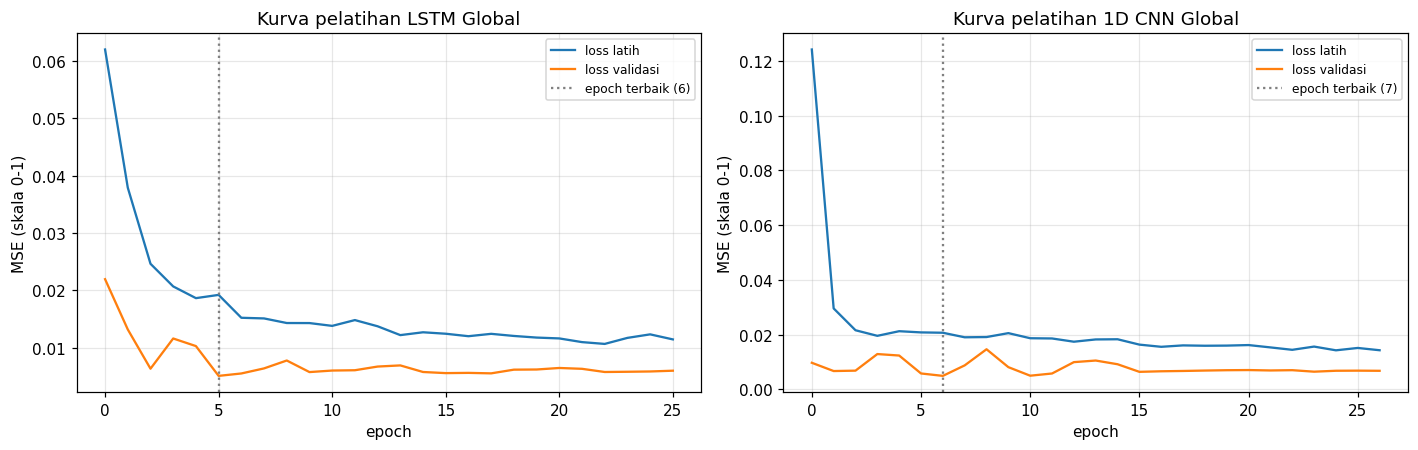

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=False)
for ax, name in zip(axes, ["LSTM Global", "1D CNN Global"]):
    history = cmp_dl_histories[name]
    ax.plot(history["loss"], label="loss latih")
    ax.plot(history["val_loss"], label="loss validasi")
    ax.axvline(cmp_dl_best_epoch[name] - 1, ls=":", color="gray",
               label=f"epoch terbaik ({cmp_dl_best_epoch[name]})")
    ax.set_title(f"Kurva pelatihan {name}")
    ax.set_xlabel("epoch")
    ax.set_ylabel("MSE (skala 0-1)")
    ax.legend(fontsize=8)

fig.tight_layout()
fig.savefig(CMP_DIR / "cmp_1_training_curves.png", dpi=120)
plt.show()


### 18.6 Evaluasi per outlet dan overall

**Per outlet:** metrik dihitung pada 28 hari masing-masing outlet.

**Overall:** aktual dan prediksi dijumlahkan per tanggal di ketiga outlet, lalu metrik dihitung pada 28 nilai harian hasil agregasi. Overall tidak dihitung dengan merata-ratakan MAE outlet.

**Penanganan nilai nol:** `MAPE` hanya memakai observasi dengan aktual tidak nol; `sMAPE` mengabaikan observasi dengan penyebut nol; `WAPE` memakai `sum(|actual|)` sebagai penyebut. Jumlah observasi nol dilaporkan pada tabel.


In [42]:
actual_test = test_panel[["date", "outlet_id", TARGET]].rename(columns={TARGET: "actual"}).copy()

cmp_overall, cmp_per_outlet = cmp_evaluate(cmp_forecasts, actual_test)
cmp_overall = cmp_overall.sort_values("MAE").reset_index(drop=True)
cmp_overall.insert(0, "rank", np.arange(1, len(cmp_overall) + 1))
cmp_overall["family_label"] = cmp_overall.family.map(CMP_LABEL)

cmp_per_outlet = cmp_per_outlet.merge(
    cmp_overall[["model", "rank"]], on="model", how="left"
).sort_values(["rank", "outlet_id"]).reset_index(drop=True)
cmp_per_outlet["family_label"] = cmp_per_outlet.family.map(CMP_LABEL)

print("TABEL 1 - Perbandingan overall (aktual dan prediksi diagregasi per tanggal):")
print(cmp_overall[["rank", "model", "family_label", "MAE", "RMSE", "MAPE_%", "sMAPE_%", "WAPE_%", "Bias"]]
      .round(2).to_string(index=False))
print()
print("TABEL 2 - Metrik per outlet:")
print(cmp_per_outlet[["model", "family_label", "outlet_id", "MAE", "RMSE", "MAPE_%", "sMAPE_%", "WAPE_%", "Bias"]]
      .round(2).to_string(index=False))

cmp_pivot_mae = cmp_per_outlet.pivot(index="model", columns="outlet_id", values="MAE").loc[cmp_overall.model]
cmp_pivot_wape = cmp_per_outlet.pivot(index="model", columns="outlet_id", values="WAPE_%").loc[cmp_overall.model]
print()
print("MAE per outlet (rupiah):")
print(cmp_pivot_mae.round(0).to_string())
print()
print("WAPE per outlet (persen):")
print(cmp_pivot_wape.round(2).to_string())

cmp_overall.to_csv(CMP_DIR / "cmp_model_comparison_overall.csv", index=False)
cmp_per_outlet.to_csv(CMP_DIR / "cmp_model_comparison_per_outlet.csv", index=False)
cmp_pivot_mae.to_csv(CMP_DIR / "cmp_mae_per_outlet.csv")
cmp_pivot_wape.to_csv(CMP_DIR / "cmp_wape_per_outlet.csv")


TABEL 1 - Perbandingan overall (aktual dan prediksi diagregasi per tanggal):
 rank                    model     family_label       MAE      RMSE  MAPE_%  sMAPE_%  WAPE_%      Bias
    1 Gradient Boosting Global Machine Learning 203115.30 268753.27    4.97     4.98    5.02  18927.48
    2          CatBoost Global Machine Learning 215453.75 277722.05    5.35     5.28    5.32  80470.97
    3            1D CNN Global    Deep Learning 219073.70 287168.50    5.37     5.37    5.41  13924.73
    4           XGBoost Global Machine Learning 235818.88 310811.63    5.88     5.77    5.83  82970.78
    5              LSTM Global    Deep Learning 244170.04 312907.93    6.13     5.98    6.03 119612.75
    6          LightGBM Global Machine Learning 270071.19 339473.23    6.79     6.57    6.67 157950.35
    7       Seasonal Naive (7)         Baseline 520978.12 630538.65   12.91    12.40   12.87 191763.19
    8                    Naive         Baseline 697104.25 733994.88   17.67    16.07   17.22 675804

### 18.7 Visualisasi hasil

Grafik mencakup aktual vs prediksi per outlet, perbandingan total harian, serta perbandingan MAE dan WAPE seluruh model. Warna membedakan baseline, ML, dan DL.


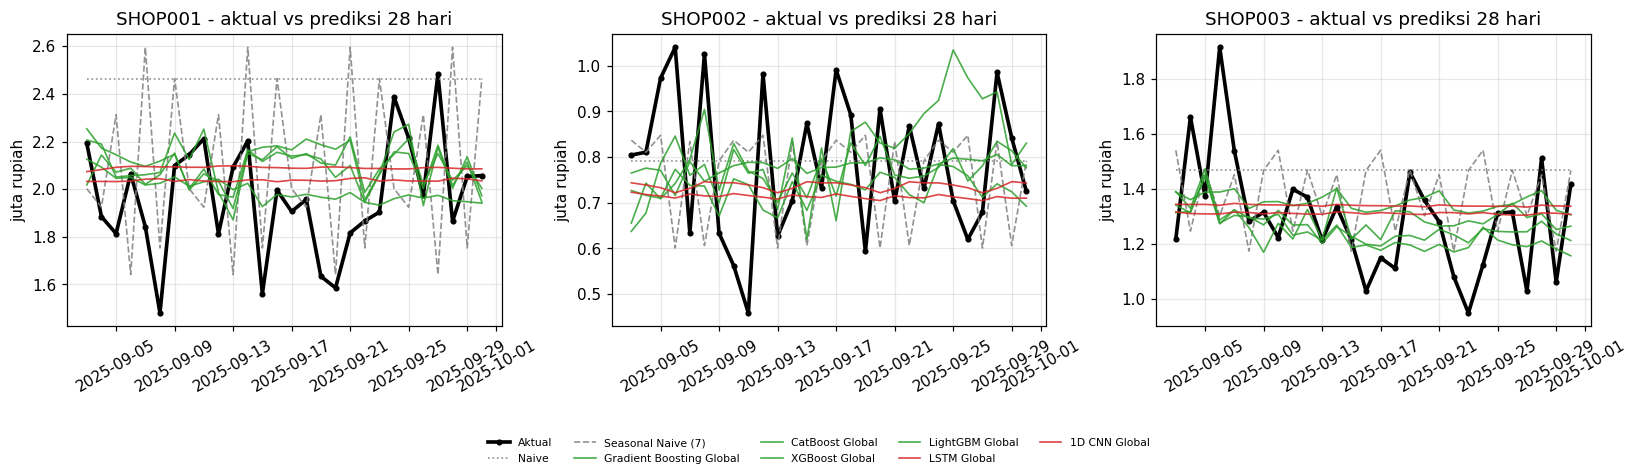

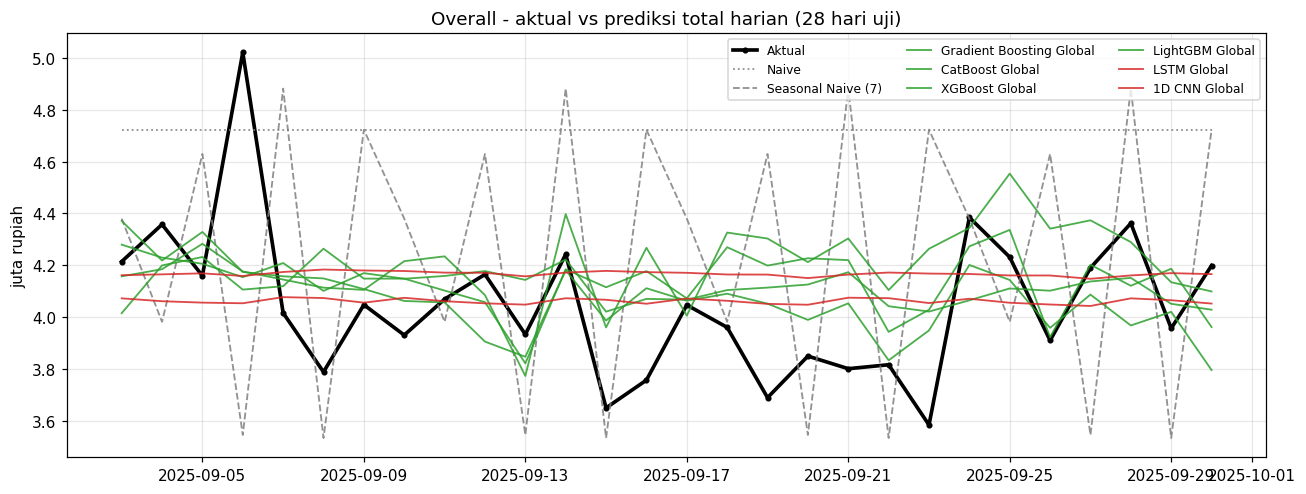

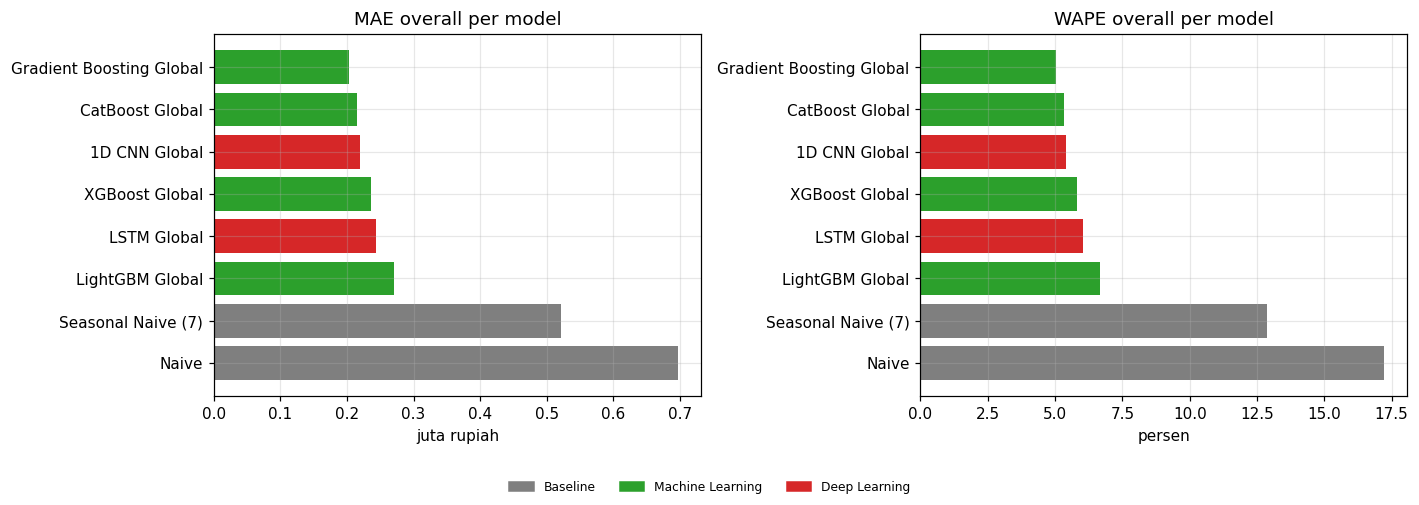

In [43]:
CMP_COLORS = {"baseline": "#7f7f7f", "ml": "#2ca02c", "dl": "#d62728"}
cmp_line_styles = {"Naive": ":", "Seasonal Naive (7)": "--"}

# Aktual vs prediksi per outlet
fig, axes = plt.subplots(1, len(outlets), figsize=(15, 4.3), sharex=True)
for ax, outlet in zip(axes, outlets):
    subset = actual_test[actual_test.outlet_id == outlet].sort_values("date")
    ax.plot(subset.date, subset.actual / 1e6, color="black", lw=2.4, marker="o", ms=3, label="Aktual")
    for name, forecast in cmp_forecasts.items():
        series = forecast[forecast.outlet_id == outlet].sort_values("date")
        ax.plot(series.date, series.prediction / 1e6, lw=1.1, alpha=0.85,
                color=CMP_COLORS[CMP_FAMILY[name]], ls=cmp_line_styles.get(name, "-"), label=name)
    ax.set_title(f"{outlet} - aktual vs prediksi 28 hari")
    ax.set_ylabel("juta rupiah")
    ax.tick_params(axis="x", rotation=30)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=5, fontsize=7, frameon=False)
fig.tight_layout(rect=(0, 0.12, 1, 1))
fig.savefig(CMP_DIR / "cmp_2_actual_vs_predicted_per_outlet.png", dpi=120)
plt.show()

# Overall: total harian seluruh outlet
actual_total_cmp = actual_test.groupby("date").actual.sum()
fig, ax = plt.subplots(figsize=(12, 4.6))
ax.plot(actual_total_cmp.index, actual_total_cmp / 1e6, color="black", lw=2.4, marker="o", ms=3, label="Aktual")
for name, forecast in cmp_forecasts.items():
    series = forecast.groupby("date").prediction.sum().reindex(actual_total_cmp.index)
    ax.plot(series.index, series / 1e6, lw=1.2, alpha=0.85,
            color=CMP_COLORS[CMP_FAMILY[name]], ls=cmp_line_styles.get(name, "-"), label=name)
ax.set_title("Overall - aktual vs prediksi total harian (28 hari uji)")
ax.set_ylabel("juta rupiah")
ax.legend(ncol=3, fontsize=8)
fig.tight_layout()
fig.savefig(CMP_DIR / "cmp_3_overall_actual_vs_predicted.png", dpi=120)
plt.show()

# MAE dan WAPE seluruh model
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
ordered = cmp_overall.sort_values("MAE", ascending=False)
bar_colors = [CMP_COLORS[family] for family in ordered.family]

axes[0].barh(ordered.model, ordered.MAE / 1e6, color=bar_colors)
axes[0].set_title("MAE overall per model")
axes[0].set_xlabel("juta rupiah")

axes[1].barh(ordered.model, ordered["WAPE_%"], color=bar_colors)
axes[1].set_title("WAPE overall per model")
axes[1].set_xlabel("persen")

from matplotlib.patches import Patch
handles = [Patch(color=CMP_COLORS[key], label=CMP_LABEL[key]) for key in ["baseline", "ml", "dl"]]
fig.legend(handles=handles, loc="lower center", ncol=3, fontsize=8, frameon=False)
fig.tight_layout(rect=(0, 0.08, 1, 1))
fig.savefig(CMP_DIR / "cmp_4_mae_wape.png", dpi=120)
plt.show()


### 18.8 Verifikasi eksperimen

Pemeriksaan berikut memastikan tidak ada model lokal yang tidak sengaja dibuat, setiap outlet mendapat 28 prediksi, tanggal prediksi selaras, tidak ada kebocoran masa depan, dan metrik dapat dihitung ulang.


In [44]:
print("VERIFIKASI EKSPERIMEN PERBANDINGAN")
print("=" * 70)

assert len(cmp_global_models) == 4, "jumlah model ML global harus empat"
assert set(cmp_global_models) == {"Gradient Boosting Global", "CatBoost Global", "XGBoost Global", "LightGBM Global"}
assert len(cmp_dl_models) == 2, "jumlah model DL global harus dua"
assert set(cmp_dl_models) == {"LSTM Global", "1D CNN Global"}
assert len(cmp_forecasts) == 8, "harus ada delapan metode"
assert set(cmp_forecasts) == set(CMP_FAMILY), "nama model tidak konsisten"
print("1. satu model global per algoritma ML (4) dan DL (2): lolos")

cmp_check_coverage(cmp_forecasts)
print("2. setiap outlet menerima 28 prediksi unik: lolos")

for name, forecast in cmp_forecasts.items():
    aligned = forecast.sort_values(ID_COLUMNS).reset_index(drop=True)
    expected = actual_test.sort_values(ID_COLUMNS).reset_index(drop=True)
    assert aligned[ID_COLUMNS].equals(expected[ID_COLUMNS]), f"{name}: prediksi tidak selaras dengan tanggal-outlet uji"
print("3. prediksi selaras dengan tanggal dan outlet yang benar: lolos")

first_test = pd.Timestamp(test_dates[0])
for outlet in outlets:
    expected_lag = hist_panel[hist_panel.outlet_id == outlet].sort_values("date")[TARGET].iloc[-1]
    observed_lag = feature_panel[
        (feature_panel.outlet_id == outlet) & (feature_panel.date == first_test)
    ].lag_1.iloc[0]
    assert np.isclose(observed_lag, expected_lag), f"lag_1 {outlet} bocor dari masa depan"
assert max(train_dates) < min(val_dates) and max(val_dates) < min(test_dates)
print("4. tidak ada nilai aktual masa depan pada fitur lag/rolling dan split kronologis: lolos")

for name, forecast in cmp_forecasts.items():
    assert set(pd.to_datetime(forecast.date)) == set(pd.to_datetime(test_dates)), f"{name}: periode uji berbeda"
print("5. seluruh model memakai periode uji 28 hari yang sama: lolos")

best_name_cmp = cmp_overall.loc[0, "model"]
merged_best = actual_test.merge(cmp_forecasts[best_name_cmp], on=ID_COLUMNS, how="inner")
daily_best = merged_best.groupby("date", as_index=False).agg(actual=("actual", "sum"), prediction=("prediction", "sum"))
recomputed = cmp_score(daily_best.actual, daily_best.prediction)
for metric in ["MAE", "RMSE", "MAPE_%", "sMAPE_%", "WAPE_%", "Bias"]:
    assert np.isclose(recomputed[metric], cmp_overall.loc[0, metric]), f"metrik {metric} tidak konsisten"
print(f"6. metrik overall dapat dihitung ulang ({best_name_cmp}): lolos")

print()
print(f"model terbaik overall: {best_name_cmp} ({CMP_LABEL[CMP_FAMILY[best_name_cmp]]})")
print(cmp_overall[["rank", "model", "MAE", "WAPE_%", "Bias"]].round(2).to_string(index=False))


VERIFIKASI EKSPERIMEN PERBANDINGAN
1. satu model global per algoritma ML (4) dan DL (2): lolos
cek cakupan lolos: 8 model x 3 outlet x 28 hari
2. setiap outlet menerima 28 prediksi unik: lolos
3. prediksi selaras dengan tanggal dan outlet yang benar: lolos
4. tidak ada nilai aktual masa depan pada fitur lag/rolling dan split kronologis: lolos
5. seluruh model memakai periode uji 28 hari yang sama: lolos
6. metrik overall dapat dihitung ulang (Gradient Boosting Global): lolos

model terbaik overall: Gradient Boosting Global (Machine Learning)
 rank                    model       MAE  WAPE_%      Bias
    1 Gradient Boosting Global 203115.30    5.02  18927.48
    2          CatBoost Global 215453.75    5.32  80470.97
    3            1D CNN Global 219073.70    5.41  13924.73
    4           XGBoost Global 235818.88    5.83  82970.78
    5              LSTM Global 244170.04    6.03 119612.75
    6          LightGBM Global 270071.19    6.67 157950.35
    7       Seasonal Naive (7) 520978.1

### 18.9 Ringkasan hasil dan pembahasan

Ringkasan di bawah dihitung langsung dari tabel evaluasi, sehingga angka yang tampil berasal dari eksekusi notebook, bukan nilai yang ditulis manual.


In [45]:
cmp_metadata = {
    "experiment": "global multi-outlet model comparison",
    "target": TARGET,
    "granularity": "harian x outlet",
    "outlets": outlets,
    "split": {
        "train": [str(pd.Timestamp(train_dates.min()).date()), str(pd.Timestamp(train_dates.max()).date())],
        "validation": [str(pd.Timestamp(val_dates.min()).date()), str(pd.Timestamp(val_dates.max()).date())],
        "test": [str(pd.Timestamp(test_dates.min()).date()), str(pd.Timestamp(test_dates.max()).date())],
    },
    "forecast_horizon_days": CMP_HORIZON,
    "features": FEATURES,
    "dl_channels": ["scaled_sales", "dow_one_hot_7", "is_weekend"],
    "dl_window": CMP_WINDOW,
    "dl_scaler": "MinMaxScaler fit pada train",
    "random_seed": SEED,
    "zero_handling": "MAPE mengabaikan aktual nol; sMAPE mengabaikan penyebut nol; WAPE memakai total aktual",
    "ml_config": cmp_ml_config,
    "dl_architecture": cmp_dl_architecture,
    "dl_best_epoch": cmp_dl_best_epoch,
    "overall_metrics": cmp_overall.drop(columns=["family_label"]).to_dict(orient="records"),
}
(CMP_DIR / "comparison_metadata.json").write_text(
    json.dumps(cmp_metadata, indent=2, ensure_ascii=False) + "\n", encoding="utf-8"
)

print("RINGKASAN PERBANDINGAN MODEL GLOBAL")
print("=" * 78)
print(f"periode uji : {pd.Timestamp(test_dates[0]).date()} s/d {pd.Timestamp(test_dates[-1]).date()} ({CMP_HORIZON} hari x {len(outlets)} outlet)")
print()
for family in ["baseline", "ml", "dl"]:
    subset = cmp_overall[cmp_overall.family == family]
    best = subset.sort_values("MAE").iloc[0]
    print(f"{CMP_LABEL[family]:<18} terbaik: {best.model:<28} MAE Rp {best.MAE:,.0f} | WAPE {best['WAPE_%']:.2f}% | Bias Rp {best.Bias:,.0f}")
print()
print("Peringkat overall:")
print(cmp_overall[["rank", "model", "MAE", "RMSE", "MAPE_%", "sMAPE_%", "WAPE_%", "Bias"]].round(2).to_string(index=False))
print()
print("Catatan: seluruh model memakai periode uji dan horizon yang sama; model global dilatih satu kali per algoritma.")


RINGKASAN PERBANDINGAN MODEL GLOBAL
periode uji : 2025-09-03 s/d 2025-09-30 (28 hari x 3 outlet)

Baseline           terbaik: Seasonal Naive (7)           MAE Rp 520,978 | WAPE 12.87% | Bias Rp 191,763
Machine Learning   terbaik: Gradient Boosting Global     MAE Rp 203,115 | WAPE 5.02% | Bias Rp 18,927
Deep Learning      terbaik: 1D CNN Global                MAE Rp 219,074 | WAPE 5.41% | Bias Rp 13,925

Peringkat overall:
 rank                    model       MAE      RMSE  MAPE_%  sMAPE_%  WAPE_%      Bias
    1 Gradient Boosting Global 203115.30 268753.27    4.97     4.98    5.02  18927.48
    2          CatBoost Global 215453.75 277722.05    5.35     5.28    5.32  80470.97
    3            1D CNN Global 219073.70 287168.50    5.37     5.37    5.41  13924.73
    4           XGBoost Global 235818.88 310811.63    5.88     5.77    5.83  82970.78
    5              LSTM Global 244170.04 312907.93    6.13     5.98    6.03 119612.75
    6          LightGBM Global 270071.19 339473.23    6.79

### 18.10 Pembahasan

**Kinerja overall.** Pada periode uji 3-30 September 2025, seluruh model global ML dan DL mengalahkan kedua baseline. Gradient Boosting Global menempati peringkat pertama (MAE Rp 203.115; WAPE 5,02%; bias +Rp 18.927), diikuti CatBoost Global (MAE Rp 215.454; WAPE 5,32%) dan 1D CNN Global (MAE Rp 219.074; WAPE 5,41%). LSTM Global dan LightGBM Global berada di bawahnya, sedangkan Seasonal Naive (7) dan Naive menutup peringkat dengan WAPE 12,87% dan 17,22%. Dibanding Seasonal Naive (7), Gradient Boosting Global menurunkan MAE sekitar 61%; dibanding Naive, penurunannya sekitar 71%.

**Bias.** Semua model memiliki bias positif, artinya cenderung overforecast pada periode uji. Bias terkecil dimiliki 1D CNN Global (+Rp 13.925) dan Gradient Boosting Global (+Rp 18.927), sedangkan LightGBM Global (+Rp 157.950) dan Naive (+Rp 675.804) paling agresif. Karena itu, model dengan MAE rendah belum tentu paling seimbang secara arah; 1D CNN menarik karena akurasinya dekat model terbaik dengan bias paling kecil.

**Perbedaan antar outlet.** Tidak ada satu algoritma yang unggul di semua outlet. CatBoost Global paling akurat di SHOP001 (MAE Rp 180.218; WAPE 9,16%), LSTM Global paling akurat di SHOP002 (MAE Rp 132.996; WAPE 16,94%), dan XGBoost Global paling akurat di SHOP003 (MAE Rp 148.384; WAPE 11,46%). SHOP002 paling sulit secara relatif: WAPE model global berada di kisaran 17-21%, lebih tinggi daripada SHOP001 dan SHOP003 yang berada di kisaran 9-12%. Sebaliknya, Naive cukup kompetitif di SHOP002 karena level penjualan outlet tersebut relatif datar, tetapi buruk di SHOP001 dan SHOP003 yang memiliki perubahan level.

**Model global versus baseline.** Model global memanfaatkan pola mingguan bersama sekaligus membedakan level outlet melalui `outlet_id`. Keunggulan besarnya terhadap baseline menunjukkan bahwa lag, rolling statistic, dan kalender memberi informasi yang tidak ditangkap aturan naive. Di sisi lain, perbedaan antar algoritma relatif kecil dibandingkan jarak ke baseline, sehingga pemilihan model sebaiknya mempertimbangkan akurasi, bias, dan kemudahan operasional sekaligus.

**Deep learning.** Dengan hanya 564 sequence latih (216 hari x 3 outlet, window 28), LSTM dan 1D CNN tetap kompetitif. 1D CNN sedikit lebih baik daripada LSTM secara overall (MAE Rp 219.074 versus Rp 244.170), sedangkan LSTM unggul di SHOP002. Conv1D kausal dengan global average pooling lebih stabil pada data terbatas, sementara LSTM lebih sensitif terhadap inisialisasi dan jumlah epoch.

**Keterbatasan.** Evaluasi memakai satu jendela uji 28 hari sehingga belum mengukur stabilitas antar periode; validasi bergulir (rolling-origin) dapat ditambahkan pada penelitian lanjutan. Hyperparameter CatBoost dipilih pada validation, sedangkan algoritma lain memakai konfigurasi tetap dari eksperimen asli agar perbandingan fokus pada algoritma, bukan pada intensitas tuning. Model deep learning memiliki variasi acak antar eksekusi meskipun seed sudah ditetapkan.

**Implikasi praktis.** Untuk akurasi overall, Gradient Boosting Global adalah pilihan utama. Jika keseimbangan akurasi dan bias lebih penting, 1D CNN Global layak dipertimbangkan. Untuk outlet tertentu, model terbaik dapat berbeda: CatBoost untuk SHOP001, LSTM untuk SHOP002, dan XGBoost untuk SHOP003. Perbedaan ini menunjukkan bahwa strategi global tetap perlu dievaluasi per outlet, bukan hanya dari agregat total.


In [46]:
import shutil

NOTEBOOK_NAME = "sales_forecast"
NOTEBOOK_VERSION = "1.0.0"
API_DIR = Path("..").resolve().parent / "API" / "artifacts" / "sales_forecast" / NOTEBOOK_VERSION
API_DIR.mkdir(parents=True, exist_ok=True)

api_metadata = json.loads((OUTPUT_DIR / "metadata.json").read_text(encoding="utf-8"))
api_metadata.update({
    "model_id": "sales_forecast",
    "model_version": NOTEBOOK_VERSION,
    "source_notebook": NOTEBOOK_NAME,
})

shutil.copy2(OUTPUT_DIR / "model.pkl", API_DIR / "model.pkl")
(API_DIR / "metadata.json").write_text(
    json.dumps(api_metadata, indent=2, ensure_ascii=False) + "\n",
    encoding="utf-8",
)

print(f"{NOTEBOOK_NAME} versi {NOTEBOOK_VERSION} diekspor ke:")
print(" ", API_DIR)
for path in sorted(API_DIR.iterdir()):
    print(f"   {path.name:<20} {path.stat().st_size / 1024:>9.1f} KB")

sales_forecast versi 1.0.0 diekspor ke:
  C:\Users\Radit\Politeknik Negeri Malang\Semester 5\ProjectBasedLearning_MyVentory\API\artifacts\sales_forecast\1.0.0
   metadata.json              5.8 KB
   model.pkl                530.5 KB
